# DroneWaste: Aerial Waste Detection with YOLOv12

**Milestone 2 — dataset preparation, site-wise split construction, model training and evaluation**

This notebook contains the main experimental workflow for the DroneWaste project. It prepares the dataset, creates reproducible site-wise cross-validation manifests, trains YOLOv12 Nano and Small on Fold 1, and evaluates both checkpoints on the held-out Fold 1 test site.

**Important scope note:** the notebook creates manifests for all 17 site-wise folds, but the training and test evaluation recorded here cover **Fold 1 only**. Do not describe the 17-fold experiment as completed until all folds have been trained and evaluated.

**Runtime:** Google Colab with Google Drive mounted and a CUDA GPU (the recorded runs used a Tesla T4).

**Storage:** source dataset and persistent results are stored in `/content/drive/MyDrive/DroneWaste`; temporary working files are stored under `/content/dronewaste_work`.

Run the cells in order in a fresh Colab runtime. Cells labelled as historical diagnostics or recovery checks are retained for traceability and may be skipped when their prerequisite files already exist.


In [ ]:
# ============================================================
# CELL 1 — MOUNT GOOGLE DRIVE & CHECK STORAGE
# Gist: Connect Drive and inspect the new workspace.
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import shutil

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
DRIVE_ROOT.mkdir(parents=True, exist_ok=True)

total, used, free = shutil.disk_usage("/content")

print("Google Drive mounted successfully.")
print("Project folder:", DRIVE_ROOT)
print(f"Colab temporary storage free: {free / (1024**3):.2f} GB")
print("\nNext: upload the original dataset files into the Drive project folder.")

Mounted at /content/drive
Google Drive mounted successfully.
Project folder: /content/drive/MyDrive/DroneWaste
Colab temporary storage free: 87.20 GB

Next: upload the original dataset files into the Drive project folder.


## 1. Dataset access and initial inspection

Mount Google Drive, verify source files, and inspect the DroneWaste annotations and image archive.

In [ ]:
# ============================================================
# CELL 2 — VERIFY DATASET FILES
# Gist: Confirm both source files exist and check their sizes.
# ============================================================

from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")

IMAGE_ARCHIVE = DRIVE_ROOT / "images.tar.gz"
ANNOTATIONS = DRIVE_ROOT / "dronewaste_v1.0.json"

files = {
    "Image archive": IMAGE_ARCHIVE,
    "Annotation JSON": ANNOTATIONS,
}

all_found = True

for name, path in files.items():
    if path.exists():
        size_mb = path.stat().st_size / (1024 ** 2)
        print(f"✅ {name}: {path.name} ({size_mb:.2f} MB)")
    else:
        print(f"❌ {name} not found: {path}")
        all_found = False

if all_found:
    print("\n✅ Both source files are present. Ready for dataset inspection.")
else:
    print("\n⚠️ Upload the missing file(s), then rerun this cell.")

✅ Image archive: images.tar.gz (3702.61 MB)
✅ Annotation JSON: dronewaste_v1.0.json (8.40 MB)

✅ Both source files are present. Ready for dataset inspection.


In [ ]:
# ============================================================
# CELL 3 — INSPECT DRONEWASTE ANNOTATIONS
# Gist: Understand the dataset structure before preprocessing.
# ============================================================

import json
from pathlib import Path
from collections import Counter

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"

with open(JSON_PATH, "r") as f:
    dataset = json.load(f)

images = dataset.get("images", [])
annotations = dataset.get("annotations", [])
categories = dataset.get("categories", [])

print("=" * 60)
print("DATASET OVERVIEW")
print("=" * 60)
print("Top-level JSON keys:", list(dataset.keys()))
print("Total images:", len(images))
print("Total annotations:", len(annotations))
print("Total classes:", len(categories))

print("\n" + "=" * 60)
print("CLASS NAMES AND IDS")
print("=" * 60)

for category in sorted(categories, key=lambda c: c["id"]):
    print(f'{category["id"]:>2}: {category["name"]}')

print("\n" + "=" * 60)
print("IMAGE METADATA EXAMPLE")
print("=" * 60)

if images:
    print(json.dumps(images[0], indent=2))

print("\n" + "=" * 60)
print("ANNOTATION EXAMPLE")
print("=" * 60)

if annotations:
    print(json.dumps(annotations[0], indent=2))

print("\n" + "=" * 60)
print("SITE DISTRIBUTION")
print("=" * 60)

import re

site_counts = Counter()
unmatched_names = []

for image_info in images:
    filename = Path(image_info.get("file_name", "")).name
    match = re.match(r"site(\d+)_", filename, re.IGNORECASE)

    if match:
        site_counts[int(match.group(1))] += 1
    else:
        unmatched_names.append(filename)

for site, count in sorted(site_counts.items()):
    print(f"Site {site}: {count} images")

print("Images with unrecognized site filenames:", len(unmatched_names))
if unmatched_names:
    print("Examples:", unmatched_names[:5])

print("\n✅ Annotation inspection complete.")

DATASET OVERVIEW
Top-level JSON keys: ['info', 'categories', 'images', 'annotations']
Total images: 4993
Total annotations: 5135
Total classes: 20

CLASS NAMES AND IDS
 1: Rubble
 2: Construction and demolition materials
 3: Asphalt milling
 4: Excavation materials
 5: Appliances
 6: Electronic equipment
 7: Furniture
 8: Metal barrels
 9: Plastic packaging
10: Wood
11: Pallets
12: Scrap
13: Plastic
14: Vehicles
15: Tyres
16: Paper
17: Foundry
18: Asbestos
19: Textile
20: Mixed items

IMAGE METADATA EXAMPLE
{
  "id": 1,
  "file_name": "site3_4.png",
  "site": "site3",
  "width": 640,
  "height": 640
}

ANNOTATION EXAMPLE
{
  "id": 1,
  "image_id": 23,
  "category_id": 15,
  "iscrowd": 0,
  "area": 606.5,
  "bbox": [
    329.0,
    394.0,
    28.0,
    27.0
  ],
  "segmentation": [
    [
      329.0,
      402.0,
      329.0,
      412.0,
      332.0,
      417.0,
      339.0,
      421.0,
      347.0,
      421.0,
      351.0,
      419.0,
      355.0,
      415.0,
      357.0,
      4

## 2. Dataset audit and annotation preparation

Validate the source images and COCO annotations, convert bounding boxes to YOLO labels, and check label integrity.

**Historical note:** The early site-wise plans below are exploratory drafts, not the canonical split used for the recorded Fold 1 experiment. The final manifest is generated in the later section titled “Create official-style CV manifests.”

In [ ]:
# ============================================================
# PRELIMINARY PLAN (SUPERSEDED) — EARLY SITE-WISE CV DRAFT
# Historical draft only. The canonical manifest is generated later.
# ============================================================

import json
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"

with open(JSON_PATH, "r") as f:
    dataset = json.load(f)

# Read the sites directly from the dataset metadata.
all_sites = sorted({
    int(image["site"].lower().replace("site", ""))
    for image in dataset["images"]
})

# The published approach holds out one site for testing per fold.
# We will rotate the test site across all 17 sites.
folds = []

for fold_number, test_site in enumerate(all_sites, start=1):
    remaining_sites = [s for s in all_sites if s != test_site]

    # Deterministic validation-site selection:
    # use the next site in sorted order, wrapping around if necessary.
    test_index = all_sites.index(test_site)
    val_site = all_sites[(test_index + 1) % len(all_sites)]

    train_sites = [
        s for s in remaining_sites if s != val_site
    ]

    folds.append({
        "fold": fold_number,
        "train_sites": train_sites,
        "val_sites": [val_site],
        "test_sites": [test_site],
    })

# Save the experiment plan.
PLAN_PATH = DRIVE_ROOT / "sitewise_cv_plan.json"
with open(PLAN_PATH, "w") as f:
    json.dump({
        "dataset": "DroneWaste",
        "number_of_sites": len(all_sites),
        "number_of_folds": len(folds),
        "protocol": "site-wise cross-validation",
        "folds": folds,
    }, f, indent=2)

print("Sites:", all_sites)
print("Number of folds:", len(folds))
print("Saved plan:", PLAN_PATH)

print("\nFirst three folds:")
for fold in folds[:3]:
    print(
        f"Fold {fold['fold']}: "
        f"train={len(fold['train_sites'])} sites, "
        f"val={fold['val_sites']}, "
        f"test={fold['test_sites']}"
    )

print("\n✅ Cross-validation plan saved.")

Sites: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Number of folds: 17
Saved plan: /content/drive/MyDrive/DroneWaste/sitewise_cv_plan.json

First three folds:
Fold 1: train=15 sites, val=[2], test=[1]
Fold 2: train=15 sites, val=[3], test=[2]
Fold 3: train=15 sites, val=[4], test=[3]

✅ Cross-validation plan saved.


In [ ]:
# ============================================================
# CELL 5 — INSPECT ARCHIVE STRUCTURE
# Gist: Check image paths and archive integrity before extraction.
# ============================================================

from pathlib import Path
import tarfile

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
ARCHIVE_PATH = DRIVE_ROOT / "images.tar.gz"

with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
    members = tar.getmembers()

    files = [m for m in members if m.isfile()]
    image_files = [
        m for m in files
        if m.name.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    print("Total archive entries:", len(members))
    print("Total files:", len(files))
    print("Image files:", len(image_files))
    print("\nFirst 20 image paths:")

    for member in image_files[:20]:
        print(member.name)

    print("\nArchive top-level folders:")
    top_levels = sorted({
        m.name.split("/")[0]
        for m in members
        if m.name
    })
    print(top_levels)

print("\n✅ Archive inspection complete.")

Total archive entries: 4994
Total files: 4993
Image files: 4993

First 20 image paths:
images/site3_4.png
images/site3_5.png
images/site3_6.png
images/site3_7.png
images/site3_8.png
images/site3_9.png
images/site3_10.png
images/site3_11.png
images/site3_12.png
images/site3_13.png
images/site3_14.png
images/site3_15.png
images/site3_16.png
images/site3_17.png
images/site3_18.png
images/site3_19.png
images/site3_20.png
images/site3_21.png
images/site3_22.png
images/site3_23.png

Archive top-level folders:
['images']

✅ Archive inspection complete.


In [ ]:
# ============================================================
# CELL 6 — EXTRACT DATASET
# Gist: Extract images to temporary Colab storage.
# ============================================================

from pathlib import Path
import tarfile
import shutil

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
ARCHIVE_PATH = DRIVE_ROOT / "images.tar.gz"
EXTRACT_ROOT = Path("/content/dronewaste_work")
IMAGE_ROOT = EXTRACT_ROOT / "images"

# Create a clean extraction directory
EXTRACT_ROOT.mkdir(parents=True, exist_ok=True)

if IMAGE_ROOT.exists():
    shutil.rmtree(IMAGE_ROOT)

IMAGE_ROOT.mkdir(parents=True, exist_ok=True)

# Extract only files under the expected images/ directory.
with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
    members = tar.getmembers()

    for member in members:
        if not member.isfile():
            continue

        member_path = Path(member.name)

        # Reject unexpected paths and prevent path traversal.
        if (
            member_path.is_absolute()
            or ".." in member_path.parts
            or not member.name.startswith("images/")
        ):
            raise ValueError(f"Unexpected archive path: {member.name}")

    tar.extractall(path=EXTRACT_ROOT, filter="data")

# Verify extracted image count
extracted_images = list(IMAGE_ROOT.glob("*.png"))
extracted_images += list(IMAGE_ROOT.glob("*.jpg"))
extracted_images += list(IMAGE_ROOT.glob("*.jpeg"))

print("Extraction directory:", IMAGE_ROOT)
print("Extracted images:", len(extracted_images))
print("Expected images: 4993")
print("Count matches:", len(extracted_images) == 4993)

assert len(extracted_images) == 4993, (
    f"Expected 4993 images, found {len(extracted_images)}"
)

print("\n✅ Dataset extraction and count verification complete.")

Extraction directory: /content/dronewaste_work/images
Extracted images: 4993
Expected images: 4993
Count matches: True

✅ Dataset extraction and count verification complete.


In [ ]:
# ============================================================
# CELL 7 — VERIFY IMAGES AGAINST JSON
# Gist: Validate filenames, dimensions, and dataset consistency.
# ============================================================

from pathlib import Path
from collections import Counter
from PIL import Image
import json

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
IMAGE_ROOT = Path("/content/dronewaste_work/images")
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

# Index extracted images by filename
image_files = {
    p.name: p
    for p in IMAGE_ROOT.iterdir()
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg"}
}

metadata_images = coco["images"]
metadata_by_name = {img["file_name"]: img for img in metadata_images}

missing_files = sorted(set(metadata_by_name) - set(image_files))
unexpected_files = sorted(set(image_files) - set(metadata_by_name))

dimension_mismatches = []
unreadable_images = []

for filename, metadata in metadata_by_name.items():
    path = image_files.get(filename)

    if path is None:
        continue

    try:
        with Image.open(path) as img:
            actual_width, actual_height = img.size

        if (
            actual_width != metadata["width"]
            or actual_height != metadata["height"]
        ):
            dimension_mismatches.append({
                "filename": filename,
                "json_size": (metadata["width"], metadata["height"]),
                "actual_size": (actual_width, actual_height),
            })
    except Exception as e:
        unreadable_images.append((filename, str(e)))

site_counts = Counter(img["site"] for img in metadata_images)

print("JSON image entries:", len(metadata_images))
print("Extracted image files:", len(image_files))
print("Missing files:", len(missing_files))
print("Unexpected files:", len(unexpected_files))
print("Dimension mismatches:", len(dimension_mismatches))
print("Unreadable images:", len(unreadable_images))

print("\nImages by site:")
for site, count in sorted(
    site_counts.items(),
    key=lambda item: int(item[0].replace("site", ""))
):
    print(f"{site}: {count}")

if missing_files:
    print("\nMissing examples:", missing_files[:10])

if unexpected_files:
    print("\nUnexpected examples:", unexpected_files[:10])

if dimension_mismatches:
    print("\nDimension mismatch examples:", dimension_mismatches[:5])

if unreadable_images:
    print("\nUnreadable examples:", unreadable_images[:5])

assert not missing_files, "Some metadata images are missing."
assert not unexpected_files, "Some extracted files are absent from metadata."
assert not dimension_mismatches, "Some image dimensions do not match metadata."
assert not unreadable_images, "Some images could not be opened."

print("\n✅ Image-to-metadata validation passed.")

JSON image entries: 4993
Extracted image files: 4993
Missing files: 0
Unexpected files: 0
Dimension mismatches: 0
Unreadable images: 0

Images by site:
site1: 119
site2: 130
site3: 698
site4: 182
site5: 217
site6: 813
site7: 6
site8: 210
site9: 83
site10: 17
site11: 825
site12: 186
site13: 169
site14: 279
site15: 136
site16: 848
site17: 75

✅ Image-to-metadata validation passed.


In [ ]:
# ============================================================
# CELL 8 — AUDIT COCO ANNOTATIONS
# Gist: Validate categories, bounding boxes, and class counts.
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict
import json

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = sorted(coco["categories"], key=lambda c: c["id"])

image_ids = {img["id"] for img in images}
category_ids = {cat["id"] for cat in categories}

# Index image metadata
image_info = {img["id"]: img for img in images}

# Count annotations by category and image
class_counts = Counter()
annotations_per_image = Counter()
invalid_annotations = []

for ann in annotations:
    image_id = ann.get("image_id")
    category_id = ann.get("category_id")
    bbox = ann.get("bbox")

    if image_id not in image_ids:
        invalid_annotations.append(
            (ann.get("id"), "unknown image_id", image_id)
        )
        continue

    if category_id not in category_ids:
        invalid_annotations.append(
            (ann.get("id"), "unknown category_id", category_id)
        )
        continue

    if (
        not isinstance(bbox, list)
        or len(bbox) != 4
        or not all(isinstance(v, (int, float)) for v in bbox)
    ):
        invalid_annotations.append(
            (ann.get("id"), "invalid bbox format", bbox)
        )
        continue

    x, y, w, h = bbox
    img = image_info[image_id]

    if (
        w <= 0
        or h <= 0
        or x < 0
        or y < 0
        or x + w > img["width"] + 1e-6
        or y + h > img["height"] + 1e-6
    ):
        invalid_annotations.append(
            (ann.get("id"), "bbox outside image or non-positive", bbox)
        )
        continue

    class_counts[category_id] += 1
    annotations_per_image[image_id] += 1

empty_images = [
    img for img in images
    if annotations_per_image[img["id"]] == 0
]

print("Images:", len(images))
print("Annotations:", len(annotations))
print("Categories:", len(categories))
print("Images with annotations:", len(images) - len(empty_images))
print("Images without annotations:", len(empty_images))
print("Invalid annotations:", len(invalid_annotations))

print("\nClass distribution:")
print(f"{'COCO ID':<10}{'Class name':<42}{'Annotations':>12}")

for cat in categories:
    print(
        f"{cat['id']:<10}"
        f"{cat['name']:<42}"
        f"{class_counts[cat['id']]:>12}"
    )

if invalid_annotations:
    print("\nFirst 10 invalid annotations:")
    for item in invalid_annotations[:10]:
        print(item)

assert len(categories) == 20, "Expected 20 categories."
assert not invalid_annotations, "Invalid annotations found."

print("\n✅ Annotation audit passed.")

Images: 4993
Annotations: 5135
Categories: 20
Images with annotations: 1171
Images without annotations: 3822
Invalid annotations: 0

Class distribution:
COCO ID   Class name                                 Annotations
1         Rubble                                             161
2         Construction and demolition materials              397
3         Asphalt milling                                      1
4         Excavation materials                               102
5         Appliances                                          35
6         Electronic equipment                                11
7         Furniture                                          189
8         Metal barrels                                      172
9         Plastic packaging                                  342
10        Wood                                               175
11        Pallets                                           1016
12        Scrap                                              394
13

In [ ]:
# ============================================================
# CELL 9 — CONVERT COCO ANNOTATIONS TO YOLO FORMAT
# Gist: Create normalized YOLO labels and preserve empty images.
# ============================================================

from pathlib import Path
from collections import Counter
import json

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"
LABEL_ROOT = DRIVE_ROOT / "yolo_labels"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = sorted(coco["categories"], key=lambda c: c["id"])

# Map original COCO category IDs to contiguous YOLO IDs: 0–19.
category_to_yolo = {
    cat["id"]: index
    for index, cat in enumerate(categories)
}

class_names = [cat["name"] for cat in categories]

# Group annotations by image.
annotations_by_image = {}
for ann in annotations:
    annotations_by_image.setdefault(ann["image_id"], []).append(ann)

# Recreate the label directory to avoid stale label files.
if LABEL_ROOT.exists():
    import shutil
    shutil.rmtree(LABEL_ROOT)

LABEL_ROOT.mkdir(parents=True, exist_ok=True)

written_labels = 0
empty_labels = 0
written_boxes = 0
class_counts_yolo = Counter()

for img in images:
    image_id = img["id"]
    filename = Path(img["file_name"]).stem
    label_path = LABEL_ROOT / f"{filename}.txt"

    width = img["width"]
    height = img["height"]
    lines = []

    for ann in annotations_by_image.get(image_id, []):
        x, y, w, h = ann["bbox"]

        # COCO xywh (pixel coordinates) -> YOLO normalized xywh.
        x_center = (x + w / 2) / width
        y_center = (y + h / 2) / height
        norm_width = w / width
        norm_height = h / height

        class_id = category_to_yolo[ann["category_id"]]

        lines.append(
            f"{class_id} "
            f"{x_center:.8f} "
            f"{y_center:.8f} "
            f"{norm_width:.8f} "
            f"{norm_height:.8f}"
        )

        class_counts_yolo[class_id] += 1
        written_boxes += 1

    # Write a label file even if the image contains no objects.
    label_path.write_text(
        "\n".join(lines) + ("\n" if lines else ""),
        encoding="utf-8"
    )

    written_labels += 1
    if not lines:
        empty_labels += 1

# Save the class mapping and conversion summary.
mapping = {
    "names": class_names,
    "coco_category_id_to_yolo_class_id": {
        str(k): v for k, v in category_to_yolo.items()
    },
    "image_count": len(images),
    "annotation_count": written_boxes,
    "empty_label_count": empty_labels,
}

with open(DRIVE_ROOT / "yolo_class_mapping.json", "w", encoding="utf-8") as f:
    json.dump(mapping, f, indent=2, ensure_ascii=False)

print("Images processed:", written_labels)
print("Label files created:", len(list(LABEL_ROOT.glob("*.txt"))))
print("Bounding boxes converted:", written_boxes)
print("Empty label files:", empty_labels)
print("YOLO class IDs:", min(category_to_yolo.values()), "to", max(category_to_yolo.values()))
print("Labels saved to:", LABEL_ROOT)

assert written_labels == 4993
assert written_boxes == 5135
assert empty_labels == 3822
assert set(category_to_yolo.values()) == set(range(20))

print("\n✅ COCO-to-YOLO conversion complete.")

Images processed: 4993
Label files created: 4993
Bounding boxes converted: 5135
Empty label files: 3822
YOLO class IDs: 0 to 19
Labels saved to: /content/drive/MyDrive/DroneWaste/yolo_labels

✅ COCO-to-YOLO conversion complete.


In [ ]:
# ============================================================
# CELL 10 — VERIFY YOLO LABELS
# Gist: Check label syntax, class IDs, bounding boxes and counts.
# ============================================================

from pathlib import Path
from collections import Counter
import json
import math

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
IMAGE_ROOT = Path("/content/dronewaste_work/images")
LABEL_ROOT = DRIVE_ROOT / "yolo_labels"
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

images = coco["images"]
expected_stems = {Path(img["file_name"]).stem for img in images}

image_stems = {
    p.stem for p in IMAGE_ROOT.iterdir()
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg"}
}
label_stems = {p.stem for p in LABEL_ROOT.glob("*.txt")}

missing_labels = sorted(image_stems - label_stems)
orphan_labels = sorted(label_stems - image_stems)
missing_expected_images = sorted(expected_stems - image_stems)

invalid_lines = []
class_counts = Counter()
box_count = 0
empty_count = 0

for label_path in sorted(LABEL_ROOT.glob("*.txt")):
    content = label_path.read_text(encoding="utf-8").strip()

    if not content:
        empty_count += 1
        continue

    for line_number, line in enumerate(content.splitlines(), start=1):
        parts = line.split()

        if len(parts) != 5:
            invalid_lines.append((label_path.name, line_number, "Expected 5 fields"))
            continue

        try:
            class_id = int(parts[0])
            coords = [float(v) for v in parts[1:]]
        except ValueError:
            invalid_lines.append((label_path.name, line_number, "Non-numeric value"))
            continue

        if not 0 <= class_id < 20:
            invalid_lines.append((label_path.name, line_number, "Class ID out of range"))
            continue

        if not all(math.isfinite(v) for v in coords):
            invalid_lines.append((label_path.name, line_number, "Non-finite coordinate"))
            continue

        x_center, y_center, width, height = coords

        if not (
            0 <= x_center <= 1
            and 0 <= y_center <= 1
            and 0 < width <= 1
            and 0 < height <= 1
            and x_center - width / 2 >= -1e-6
            and y_center - height / 2 >= -1e-6
            and x_center + width / 2 <= 1 + 1e-6
            and y_center + height / 2 <= 1 + 1e-6
        ):
            invalid_lines.append((label_path.name, line_number, "Invalid normalized box"))
            continue

        class_counts[class_id] += 1
        box_count += 1

print("Images found:", len(image_stems))
print("Label files found:", len(label_stems))
print("Missing labels:", len(missing_labels))
print("Orphan labels:", len(orphan_labels))
print("Expected images missing:", len(missing_expected_images))
print("Empty label files:", empty_count)
print("Valid boxes:", box_count)
print("Invalid label lines:", len(invalid_lines))
print("Classes represented:", len(class_counts))

if missing_labels:
    print("\nMissing label examples:", missing_labels[:10])
if orphan_labels:
    print("\nOrphan label examples:", orphan_labels[:10])
if invalid_lines:
    print("\nInvalid line examples:", invalid_lines[:10])

assert len(image_stems) == 4993
assert len(label_stems) == 4993
assert not missing_labels
assert not orphan_labels
assert not missing_expected_images
assert empty_count == 3822
assert box_count == 5135
assert not invalid_lines
assert set(class_counts) == set(range(20))

print("\n✅ YOLO label validation passed.")

Images found: 4993
Label files found: 4993
Missing labels: 0
Orphan labels: 0
Expected images missing: 0
Empty label files: 3822
Valid boxes: 5135
Invalid label lines: 0
Classes represented: 20

✅ YOLO label validation passed.


## 3. Site-wise cross-validation protocol

Construct and audit the 17-fold leave-one-site-out manifests. Each fold holds out one site for testing; the remaining sites are split into training and validation subsets.

In [ ]:
# ============================================================
# PRELIMINARY PLAN (SUPERSEDED) — SITE-WISE FOLD OUTLINE
# Historical outline only. The later iterative multilabel workflow creates the canonical manifests.
# ============================================================

from pathlib import Path
from collections import Counter
import json

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"
OUTPUT_PATH = DRIVE_ROOT / "sitewise_cv_plan.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

images = coco["images"]

# Derive the site names from the image metadata.
sites = sorted(
    {img["site"] for img in images},
    key=lambda s: int(s.replace("site", ""))
)

site_image_counts = Counter(img["site"] for img in images)

folds = []

for fold_index, test_site in enumerate(sites, start=1):
    train_sites = [site for site in sites if site != test_site]

    folds.append({
        "fold": fold_index,
        "test_site": test_site,
        "train_validation_sites": train_sites,
        "test_image_count": site_image_counts[test_site],
        "train_validation_image_count": sum(
            site_image_counts[site] for site in train_sites
        ),
        "validation_policy": (
            "Random image-level sample from the 16 non-test sites; "
            "fraction and seed to be confirmed against official implementation."
        )
    })

plan = {
    "dataset": "DroneWaste",
    "protocol": "Leave-one-site-out cross-validation",
    "number_of_sites": len(sites),
    "number_of_folds": len(folds),
    "total_images": len(images),
    "folds": folds
}

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(plan, f, indent=2)

print("Protocol:", plan["protocol"])
print("Sites:", len(sites))
print("Folds:", len(folds))
print("Saved plan:", OUTPUT_PATH)

print("\nFold overview:")
for fold in folds:
    print(
        f"Fold {fold['fold']:02d}: "
        f"test={fold['test_site']} "
        f"({fold['test_image_count']} images), "
        f"remaining={fold['train_validation_image_count']} images"
    )

assert len(sites) == 17
assert len(folds) == 17
assert all(len(fold["train_validation_sites"]) == 16 for fold in folds)
assert all(
    fold["test_site"] not in fold["train_validation_sites"]
    for fold in folds
)

print("\n✅ Corrected site-wise fold structure saved.")

Protocol: Leave-one-site-out cross-validation
Sites: 17
Folds: 17
Saved plan: /content/drive/MyDrive/DroneWaste/sitewise_cv_plan.json

Fold overview:
Fold 01: test=site1 (119 images), remaining=4874 images
Fold 02: test=site2 (130 images), remaining=4863 images
Fold 03: test=site3 (698 images), remaining=4295 images
Fold 04: test=site4 (182 images), remaining=4811 images
Fold 05: test=site5 (217 images), remaining=4776 images
Fold 06: test=site6 (813 images), remaining=4180 images
Fold 07: test=site7 (6 images), remaining=4987 images
Fold 08: test=site8 (210 images), remaining=4783 images
Fold 09: test=site9 (83 images), remaining=4910 images
Fold 10: test=site10 (17 images), remaining=4976 images
Fold 11: test=site11 (825 images), remaining=4168 images
Fold 12: test=site12 (186 images), remaining=4807 images
Fold 13: test=site13 (169 images), remaining=4824 images
Fold 14: test=site14 (279 images), remaining=4714 images
Fold 15: test=site15 (136 images), remaining=4857 images
Fold 16:

In [ ]:
# ============================================================
# CELL 12 — INSPECT OFFICIAL TRAINING CONFIGURATION
# Gist: Download repository source files for local inspection.
# ============================================================

from pathlib import Path
import urllib.request

WORK_ROOT = Path("/content/dronewaste_work")
SOURCE_ROOT = WORK_ROOT / "official_source"
SOURCE_ROOT.mkdir(parents=True, exist_ok=True)

FILES = {
    "train.sh":
        "https://raw.githubusercontent.com/lucamora/dronewaste/main/training/train.sh",
    "train.py":
        "https://raw.githubusercontent.com/lucamora/dronewaste/main/training/train.py",
    "README.md":
        "https://raw.githubusercontent.com/lucamora/dronewaste/main/README.md",
}

for filename, url in FILES.items():
    destination = SOURCE_ROOT / filename

    try:
        request = urllib.request.Request(
            url,
            headers={"User-Agent": "Mozilla/5.0"}
        )
        with urllib.request.urlopen(request, timeout=30) as response:
            content = response.read().decode("utf-8", errors="replace")

        destination.write_text(content, encoding="utf-8")
        print(f"\n--- {filename} ---")
        print("Saved to:", destination)
        print(content[:12000])
    except Exception as error:
        print(f"\nCould not retrieve {filename}: {error}")

print("\nInspection attempt complete.")


--- train.sh ---
Saved to: /content/dronewaste_work/official_source/train.sh
#!/bin/bash

# Define model architecture (yolov8, yolov12, faster)
arch="yolov8"
# Define a unique identifier for the run (default: train)
slug=""
# Get only the date because jobs can be started at different times
today=$(date +%Y-%m-%d)

# Set path to the storage folder for the dataset and results
export STORAGE="/path/to/storage"
# Set path to temporary dataset generated for each fold
export TMPDIR="/tmp"
# Set path to virtual environments folder
export ENVSDIR="envs"


if [ "$arch" == "yolov12" ]; then
    # Activate yolov12 specific venv
    source $ENVSDIR/yolov12/bin/activate
else
    # Activate generic venv
    source $ENVSDIR/waste/bin/activate
fi

# Check if slug is empty
if [ -z "$slug" ]; then
    slug="train"
fi

# Run_id: arch + today + slug
run_id="$arch"_"$today"_"$slug"

# Loop through site indices from 0 to 16 (included)
for SITE_INDEX in {0..16}; do
    # Fold_id: site_index + timestamp for 

In [ ]:
# ============================================================
# CELL 13A — INSTALL REQUIRED DEPENDENCY
# Gist: Install the official repository's multilabel splitter.
# ============================================================

%pip install -q scikit-multilearn

from skmultilearn.model_selection import iterative_train_test_split

print("✅ scikit-multilearn installed and import successful.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.4/89.4 kB 3.0 MB/s eta 0:00:00
✅ scikit-multilearn installed and import successful.


In [ ]:
# ============================================================
# CELL 13 — CREATE OFFICIAL-STYLE CV MANIFESTS
# Gist: 17 held-out sites, 10% stratified validation, seed 1337.
# ============================================================

from pathlib import Path
from collections import Counter
import json
import random
import numpy as np

from scipy.sparse import csr_matrix
from skmultilearn.model_selection import iterative_train_test_split

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"
OUTPUT_PATH = DRIVE_ROOT / "official_style_cv_manifests.json"

VALID_SPLIT = 0.10
RANDOM_SEED = 1337

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

images = coco["images"]
annotations = coco["annotations"]
categories = sorted(coco["categories"], key=lambda c: c["id"])

sites = sorted(
    {img["site"] for img in images},
    key=lambda s: int(s.replace("site", ""))
)

annotations_by_image = {}
for ann in annotations:
    annotations_by_image.setdefault(ann["image_id"], []).append(ann)

def stratified_train_val_split(selected_images):
    """Match the official repository's iterative multilabel split."""
    image_ids = [img["id"] for img in selected_images]
    category_ids = [cat["id"] for cat in categories]

    image_id_to_idx = {image_id: idx for idx, image_id in enumerate(image_ids)}
    category_id_to_idx = {
        category_id: idx for idx, category_id in enumerate(category_ids)
    }

    rows, cols, data = [], [], []

    for ann in annotations:
        image_idx = image_id_to_idx.get(ann["image_id"])
        category_idx = category_id_to_idx.get(ann["category_id"])

        if image_idx is not None and category_idx is not None:
            rows.append(image_idx)
            cols.append(category_idx)
            data.append(1)

    label_matrix = csr_matrix(
        (data, (rows, cols)),
        shape=(len(selected_images), len(categories))
    )

    sample_indices = np.array([[i] for i in range(len(selected_images))])

    random.seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)

    train_indices, _, val_indices, _ = iterative_train_test_split(
        sample_indices,
        label_matrix,
        test_size=VALID_SPLIT
    )

    train_ids = {image_ids[idx[0]] for idx in train_indices}
    val_ids = {image_ids[idx[0]] for idx in val_indices}

    return train_ids, val_ids

fold_manifests = []

for fold_num, test_site in enumerate(sites, start=1):
    # Test site is held out entirely.
    test_images = [img for img in images if img["site"] == test_site]
    pool_images = [img for img in images if img["site"] != test_site]

    train_ids, val_ids = stratified_train_val_split(pool_images)

    train_images = [img for img in pool_images if img["id"] in train_ids]
    val_images = [img for img in pool_images if img["id"] in val_ids]

    train_names = sorted(img["file_name"] for img in train_images)
    val_names = sorted(img["file_name"] for img in val_images)
    test_names = sorted(img["file_name"] for img in test_images)

    # Explicit checks against leakage and omissions.
    assert not (set(train_names) & set(val_names))
    assert not (set(train_names) & set(test_names))
    assert not (set(val_names) & set(test_names))
    assert len(train_names) + len(val_names) + len(test_names) == len(images)

    fold_manifests.append({
        "fold": fold_num,
        "test_site": test_site,
        "random_seed": RANDOM_SEED,
        "validation_fraction": VALID_SPLIT,
        "train_images": train_names,
        "val_images": val_names,
        "test_images": test_names,
        "counts": {
            "train": len(train_names),
            "val": len(val_names),
            "test": len(test_names)
        }
    })

output = {
    "protocol": "Leave-one-site-out; iterative multilabel stratified 10% validation",
    "random_seed": RANDOM_SEED,
    "validation_fraction": VALID_SPLIT,
    "number_of_folds": len(fold_manifests),
    "folds": fold_manifests
}

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(output, f, indent=2)

print("Protocol:", output["protocol"])
print("Folds:", len(fold_manifests))
print("Saved to:", OUTPUT_PATH)
print("\nFold | Test site | Train | Val | Test")

for fold in fold_manifests:
    c = fold["counts"]
    print(
        f"{fold['fold']:>4} | {fold['test_site']:<9} | "
        f"{c['train']:>5} | {c['val']:>4} | {c['test']:>4}"
    )

print("\n✅ Manifest creation and leakage checks passed.")

Protocol: Leave-one-site-out; iterative multilabel stratified 10% validation
Folds: 17
Saved to: /content/drive/MyDrive/DroneWaste/official_style_cv_manifests.json

Fold | Test site | Train | Val | Test
   1 | site1     |  4386 |  488 |  119
   2 | site2     |  4376 |  487 |  130
   3 | site3     |  3865 |  430 |  698
   4 | site4     |  4329 |  482 |  182
   5 | site5     |  4298 |  478 |  217
   6 | site6     |  3762 |  418 |  813
   7 | site7     |  4488 |  499 |    6
   8 | site8     |  4304 |  479 |  210
   9 | site9     |  4419 |  491 |   83
  10 | site10    |  4478 |  498 |   17
  11 | site11    |  3751 |  417 |  825
  12 | site12    |  4326 |  481 |  186
  13 | site13    |  4341 |  483 |  169
  14 | site14    |  4242 |  472 |  279
  15 | site15    |  4371 |  486 |  136
  16 | site16    |  3730 |  415 |  848
  17 | site17    |  4426 |  492 |   75

✅ Manifest creation and leakage checks passed.


In [ ]:
# ============================================================
# CELL 14 — INDEPENDENT MANIFEST AUDIT
# Gist: Verify fold sizes, site isolation, and image coverage.
# ============================================================

from pathlib import Path
from collections import Counter
import json

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"
MANIFEST_PATH = DRIVE_ROOT / "official_style_cv_manifests.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

all_names = {img["file_name"] for img in coco["images"]}
site_by_name = {img["file_name"]: img["site"] for img in coco["images"]}
folds = manifest["folds"]

assert len(folds) == 17
assert len(all_names) == 4993

test_sites = [fold["test_site"] for fold in folds]
assert len(set(test_sites)) == 17, "A test site is repeated."

for fold in folds:
    train = set(fold["train_images"])
    val = set(fold["val_images"])
    test = set(fold["test_images"])

    assert train.isdisjoint(val), f"Train/validation overlap in fold {fold['fold']}"
    assert train.isdisjoint(test), f"Train/test overlap in fold {fold['fold']}"
    assert val.isdisjoint(test), f"Validation/test overlap in fold {fold['fold']}"
    assert train | val | test == all_names, f"Missing/extra images in fold {fold['fold']}"
    assert all(site_by_name[name] != fold["test_site"] for name in train | val)
    assert all(site_by_name[name] == fold["test_site"] for name in test)

    assert len(train) == fold["counts"]["train"]
    assert len(val) == fold["counts"]["val"]
    assert len(test) == fold["counts"]["test"]

print("Dataset images:", len(all_names))
print("Number of folds:", len(folds))
print("Unique held-out sites:", len(set(test_sites)))
print("All folds cover every image exactly once across train/val/test.")
print("No train/validation/test overlap detected.")
print("No held-out-site leakage detected.")

print("\nFold | Test site | Train | Val | Test")
for fold in folds:
    c = fold["counts"]
    print(
        f"{fold['fold']:>4} | {fold['test_site']:<9} | "
        f"{c['train']:>5} | {c['val']:>4} | {c['test']:>4}"
    )

print("\n✅ Independent manifest audit passed.")

Dataset images: 4993
Number of folds: 17
Unique held-out sites: 17
All folds cover every image exactly once across train/val/test.
No train/validation/test overlap detected.
No held-out-site leakage detected.

Fold | Test site | Train | Val | Test
   1 | site1     |  4386 |  488 |  119
   2 | site2     |  4376 |  487 |  130
   3 | site3     |  3865 |  430 |  698
   4 | site4     |  4329 |  482 |  182
   5 | site5     |  4298 |  478 |  217
   6 | site6     |  3762 |  418 |  813
   7 | site7     |  4488 |  499 |    6
   8 | site8     |  4304 |  479 |  210
   9 | site9     |  4419 |  491 |   83
  10 | site10    |  4478 |  498 |   17
  11 | site11    |  3751 |  417 |  825
  12 | site12    |  4326 |  481 |  186
  13 | site13    |  4341 |  483 |  169
  14 | site14    |  4242 |  472 |  279
  15 | site15    |  4371 |  486 |  136
  16 | site16    |  3730 |  415 |  848
  17 | site17    |  4426 |  492 |   75

✅ Independent manifest audit passed.


## 4. Fold 1 dataset preparation

Create the class mapping, prepare Fold 1 image/label directories, and verify the generated dataset configuration.

In [ ]:
# ============================================================
# CELL 15 — CREATE YOLO CLASS CONFIGURATION
# Gist: Define all 20 classes and save the dataset metadata.
# ============================================================

from pathlib import Path
import json

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

categories = sorted(coco["categories"], key=lambda c: c["id"])
class_names = [category["name"] for category in categories]

assert len(class_names) == 20
assert len(set(class_names)) == 20

config = {
    "dataset": "DroneWaste",
    "number_of_classes": len(class_names),
    "class_names": class_names,
    "class_id_mapping": {
        str(i): name for i, name in enumerate(class_names)
    },
    "image_directory": "/content/dronewaste_work/images",
    "label_directory": str(DRIVE_ROOT / "yolo_labels"),
    "manifest_file": str(DRIVE_ROOT / "official_style_cv_manifests.json"),
    "protocol": "17-fold leave-one-site-out cross-validation",
    "validation_fraction": 0.10,
    "random_seed": 1337
}

OUTPUT_PATH = DRIVE_ROOT / "yolo_dataset_metadata.json"

with open(OUTPUT_PATH, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)

print("Dataset:", config["dataset"])
print("Number of classes:", config["number_of_classes"])
print("\nYOLO class IDs:")
for class_id, name in enumerate(class_names):
    print(f"{class_id:>2}: {name}")

print("\nSaved configuration:", OUTPUT_PATH)
print("\n✅ YOLO class configuration created.")

Dataset: DroneWaste
Number of classes: 20

YOLO class IDs:
 0: Rubble
 1: Construction and demolition materials
 2: Asphalt milling
 3: Excavation materials
 4: Appliances
 5: Electronic equipment
 6: Furniture
 7: Metal barrels
 8: Plastic packaging
 9: Wood
10: Pallets
11: Scrap
12: Plastic
13: Vehicles
14: Tyres
15: Paper
16: Foundry
17: Asbestos
18: Textile
19: Mixed items

Saved configuration: /content/drive/MyDrive/DroneWaste/yolo_dataset_metadata.json

✅ YOLO class configuration created.


In [ ]:
# ============================================================
# CELL 16 — PREPARE FOLD 1 DATASET
# Gist: Create train/val/test image and label links for Fold 1.
# ============================================================

from pathlib import Path
import json
import os

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
IMAGE_ROOT = Path("/content/dronewaste_work/images")
LABEL_ROOT = DRIVE_ROOT / "yolo_labels"
MANIFEST_PATH = DRIVE_ROOT / "official_style_cv_manifests.json"

# Keep working links in temporary Colab storage for faster access.
DATASET_ROOT = Path("/content/dronewaste_work/yolo_folds/fold_01")

with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    manifest = json.load(f)

fold = manifest["folds"][0]

# Rebuild Fold 1 cleanly if this cell is rerun.
if DATASET_ROOT.exists():
    import shutil
    shutil.rmtree(DATASET_ROOT)

for split in ("train", "val", "test"):
    (DATASET_ROOT / "images" / split).mkdir(parents=True, exist_ok=True)
    (DATASET_ROOT / "labels" / split).mkdir(parents=True, exist_ok=True)

split_names = {
    "train": fold["train_images"],
    "val": fold["val_images"],
    "test": fold["test_images"]
}

for split, filenames in split_names.items():
    for filename in filenames:
        image_src = IMAGE_ROOT / filename
        label_src = LABEL_ROOT / (Path(filename).stem + ".txt")

        image_dst = DATASET_ROOT / "images" / split / Path(filename).name
        label_dst = DATASET_ROOT / "labels" / split / (Path(filename).stem + ".txt")

        if not image_src.is_file():
            raise FileNotFoundError(f"Image missing: {image_src}")
        if not label_src.is_file():
            raise FileNotFoundError(f"Label missing: {label_src}")

        os.symlink(image_src, image_dst)
        os.symlink(label_src, label_dst)

print("Fold:", fold["fold"])
print("Held-out test site:", fold["test_site"])

for split in ("train", "val", "test"):
    image_count = len(list((DATASET_ROOT / "images" / split).iterdir()))
    label_count = len(list((DATASET_ROOT / "labels" / split).iterdir()))
    print(f"{split:>5}: {image_count} images | {label_count} labels")
    assert image_count == label_count == len(split_names[split])

print("\nDataset root:", DATASET_ROOT)
print("✅ Fold 1 links created and verified.")

Fold: 1
Held-out test site: site1
train: 4386 images | 4386 labels
  val: 488 images | 488 labels
 test: 119 images | 119 labels

Dataset root: /content/dronewaste_work/yolo_folds/fold_01
✅ Fold 1 links created and verified.


In [ ]:
# ============================================================
# CELL 17 — STORAGE AND DATASET INTEGRITY CHECK
# Gist: Confirm paths, symlinks, and available disk space.
# ============================================================

from pathlib import Path
import shutil
import os

IMAGE_ROOT = Path("/content/dronewaste_work/images")
LABEL_ROOT = Path("/content/drive/MyDrive/DroneWaste/yolo_labels")
FOLD_ROOT = Path("/content/dronewaste_work/yolo_folds/fold_01")

# Verify the source data directories.
assert IMAGE_ROOT.is_dir(), f"Image directory missing: {IMAGE_ROOT}"
assert LABEL_ROOT.is_dir(), f"Label directory missing: {LABEL_ROOT}"

# Verify Fold 1 links resolve to real files.
broken_links = []
for split in ("train", "val", "test"):
    for folder in ("images", "labels"):
        split_dir = FOLD_ROOT / folder / split
        for item in split_dir.iterdir():
            if not item.exists():
                broken_links.append(str(item))

print("Image source exists:", IMAGE_ROOT.is_dir())
print("Label source exists:", LABEL_ROOT.is_dir())
print("Broken links:", len(broken_links))

if broken_links:
    print("Examples:", broken_links[:5])
    raise RuntimeError("Broken dataset links detected.")

usage = shutil.disk_usage("/content")

print("\nColab temporary storage:")
print(f"Total:     {usage.total / (1024**3):.2f} GB")
print(f"Used:      {usage.used / (1024**3):.2f} GB")
print(f"Free:      {usage.free / (1024**3):.2f} GB")

drive_usage = shutil.disk_usage("/content/drive/MyDrive/DroneWaste")
print("\nDrive filesystem reports:")
print(f"Total:     {drive_usage.total / (1024**3):.2f} GB")
print(f"Free:      {drive_usage.free / (1024**3):.2f} GB")

print("\n✅ Integrity check passed.")

Image source exists: True
Label source exists: True
Broken links: 0

Colab temporary storage:
Total:     107.72 GB
Used:      27.85 GB
Free:      79.85 GB

Drive filesystem reports:
Total:     30.00 GB
Free:      2.23 GB

✅ Integrity check passed.


## 5. Runtime and experiment configuration

Check the GPU and software environment, then save the YOLOv12 experiment settings.

In [ ]:
# ============================================================
# CELL 18 — GPU AND PYTORCH ENVIRONMENT CHECK
# Gist: Verify that the runtime can train YOLO models.
# ============================================================

import torch
import platform

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)

    props = torch.cuda.get_device_properties(0)
    print(f"GPU memory: {props.total_memory / (1024**3):.2f} GB")

    print("\n✅ GPU is available for training.")
else:
    print("\n⚠️ No GPU detected.")
    print("Switch the Colab runtime to a GPU before proceeding.")

Python version: 3.13.15
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0
GPU memory: 14.56 GB

✅ GPU is available for training.


In [ ]:
# ============================================================
# CELL 19 — INSTALL AND VERIFY YOLOv12 FRAMEWORK
# Gist: Prepare Ultralytics and check both YOLOv12 model architectures.
# ============================================================

%pip install -q ultralytics==8.4.178

import torch
import ultralytics
from ultralytics import YOLO

print("Ultralytics version:", ultralytics.__version__)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

# Load model definitions and verify the architectures.
for model_name in ("yolo12n.pt", "yolo12s.pt"):
    model = YOLO(model_name)
    print(f"✅ Loaded architecture: {model_name}")
    del model

print("\n✅ Framework and both model architectures verified.")

In [ ]:
# ============================================================
# CELL 20B — REMOUNT GOOGLE DRIVE
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")

print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("DroneWaste folder found:", DRIVE_ROOT.is_dir())

if DRIVE_ROOT.is_dir():
    print("\nRequired files:")
    for name in [
        "official_style_cv_manifests.json",
        "yolo_dataset_metadata.json",
        "dronewaste_v1.0.json",
        "experiment_config.json"
    ]:
        print(f"{name}: {'FOUND' if (DRIVE_ROOT / name).is_file() else 'MISSING'}")
else:
    print("Check that you authorized the correct Google account.")

Drive mounted: True
DroneWaste folder found: True

Required files:
official_style_cv_manifests.json: FOUND
yolo_dataset_metadata.json: FOUND
dronewaste_v1.0.json: FOUND
experiment_config.json: MISSING


In [ ]:
# ============================================================
# CELL 20 — DEFINE REPRODUCIBLE EXPERIMENT SETTINGS
# ============================================================

from pathlib import Path
import json
import torch

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
WORK_ROOT = Path("/content/dronewaste_work")
EXPERIMENT_ROOT = WORK_ROOT / "experiments"
EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)

assert torch.cuda.is_available(), "GPU is not available."
assert (DRIVE_ROOT / "official_style_cv_manifests.json").is_file()
assert (DRIVE_ROOT / "yolo_dataset_metadata.json").is_file()

CONFIG = {
    "project": "DroneWaste aerial image detection",
    "framework": "Ultralytics YOLOv12",
    "models": {
        "nano": "yolo12n.pt",
        "small": "yolo12s.pt"
    },
    "evaluation_protocol": "17-fold leave-one-site-out",
    "validation_fraction": 0.10,
    "random_seed": 1337,
    "epochs": 50,
    "image_size": 640,
    "batch_size": 8,
    "device": 0,
    "workers": 2,
    "patience": 15,
    "pretrained": True,
    "save_period": 10,
    "save_to_drive_during_training": False,
    "output_directory": str(EXPERIMENT_ROOT),
    "notes": [
        "Nano and small use identical training settings.",
        "Batch size is selected conservatively for the Tesla T4.",
        "The epoch budget is an initial experimental choice, not the paper's exact setting.",
        "This is a YOLOv12 Nano-versus-Small comparison using the site-wise evaluation protocol; it is not a full 17-fold reproduction of the paper."
    ]
}

CONFIG_PATH = DRIVE_ROOT / "experiment_config.json"

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, indent=2)

print("GPU:", torch.cuda.get_device_name(0))
print("Models:", CONFIG["models"])
print("Epochs:", CONFIG["epochs"])
print("Image size:", CONFIG["image_size"])
print("Batch size:", CONFIG["batch_size"])
print("Cross-validation folds:", 17)
print("Planned full experiment runs:", 34)
print("Temporary output:", EXPERIMENT_ROOT)
print("Configuration saved:", CONFIG_PATH)
print("\n✅ Experiment configuration saved.")

## 6. Runtime recovery and data integrity checks

These cells restore temporary image files and rebuild Fold 1 after a Colab runtime reset. Use them when the temporary workspace has been cleared.

In [ ]:
# ============================================================
# CELL 21 — VERIFY DATA PERSISTENCE AFTER RUNTIME SWITCH
# ============================================================

from pathlib import Path
import json
import torch

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
IMAGE_ROOT = Path("/content/dronewaste_work/images")
LABEL_ROOT = DRIVE_ROOT / "yolo_labels"
FOLD_ROOT = Path("/content/dronewaste_work/yolo_folds/fold_01")

checks = {
    "GPU available": torch.cuda.is_available(),
    "Original dataset JSON": (DRIVE_ROOT / "dronewaste_v1.0.json").is_file(),
    "CV manifests": (DRIVE_ROOT / "official_style_cv_manifests.json").is_file(),
    "YOLO metadata": (DRIVE_ROOT / "yolo_dataset_metadata.json").is_file(),
    "Experiment config": (DRIVE_ROOT / "experiment_config.json").is_file(),
    "Extracted image directory": IMAGE_ROOT.is_dir(),
    "YOLO label directory": LABEL_ROOT.is_dir(),
    "Fold 1 dataset directory": FOLD_ROOT.is_dir(),
}

for name, passed in checks.items():
    print(f"{'✅' if passed else '❌'} {name}: {passed}")

if IMAGE_ROOT.is_dir():
    print("\nExtracted images:", len(list(IMAGE_ROOT.rglob("*.png"))))

if LABEL_ROOT.is_dir():
    print("YOLO label files:", len(list(LABEL_ROOT.glob("*.txt"))))

if FOLD_ROOT.is_dir():
    for split in ("train", "val", "test"):
        image_dir = FOLD_ROOT / "images" / split
        count = len(list(image_dir.iterdir())) if image_dir.is_dir() else 0
        print(f"Fold 1 {split} images:", count)

print("\nCheck complete. No training started.")

✅ GPU available: True
✅ Original dataset JSON: True
✅ CV manifests: True
✅ YOLO metadata: True
✅ Experiment config: True
❌ Extracted image directory: False
✅ YOLO label directory: True
❌ Fold 1 dataset directory: False
YOLO label files: 4993

Check complete. No training started.


In [ ]:
# ============================================================
# CELL 22 — RESTORE IMAGES AFTER RUNTIME RESET
# ============================================================

from pathlib import Path
import tarfile
import shutil

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
ARCHIVE_PATH = DRIVE_ROOT / "images.tar.gz"
WORK_ROOT = Path("/content/dronewaste_work")
IMAGE_ROOT = WORK_ROOT / "images"

assert ARCHIVE_PATH.is_file(), f"Image archive not found: {ARCHIVE_PATH}"

WORK_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Archive size: {ARCHIVE_PATH.stat().st_size / (1024**3):.2f} GB")
print("Checking archive contents...")

with tarfile.open(ARCHIVE_PATH, "r:gz") as tar:
    members = tar.getmembers()

    # Only allow the expected images/ directory and its contents.
    safe_members = []
    for member in members:
        path = Path(member.name)
        if path.is_absolute() or ".." in path.parts:
            raise RuntimeError(f"Unsafe archive path: {member.name}")

        if path.parts and path.parts[0] == "images":
            safe_members.append(member)

    image_members = [
        m for m in safe_members
        if m.isfile() and Path(m.name).suffix.lower() in {".png", ".jpg", ".jpeg"}
    ]

    print("Image files in archive:", len(image_members))
    assert len(image_members) == 4993, "Unexpected image count in archive."

    if IMAGE_ROOT.exists():
        shutil.rmtree(IMAGE_ROOT)

    IMAGE_ROOT.mkdir(parents=True, exist_ok=True)

    # Extract only the validated images/ members.
    tar.extractall(
        path=WORK_ROOT,
        members=safe_members,
        filter="data"
    )

actual_images = sum(
    1 for p in IMAGE_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg"}
)

print("Extracted images:", actual_images)
print("Image directory:", IMAGE_ROOT)

assert actual_images == 4993, "Extracted image count does not match."
print("\n✅ Image restoration complete.")


Archive size: 3.62 GB
Checking archive contents...
Image files in archive: 4993
Extracted images: 4993
Image directory: /content/dronewaste_work/images

✅ Image restoration complete.


In [ ]:
# ============================================================
# CELL 24 — CREATE FOLD 1 YOLO DATASET YAML
# ============================================================

from pathlib import Path
import json
import yaml

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
DATASET_ROOT = Path("/content/dronewaste_work/yolo_folds/fold_01")
METADATA_PATH = DRIVE_ROOT / "yolo_dataset_metadata.json"

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

class_names = metadata["class_names"]

assert len(class_names) == 20
assert (DATASET_ROOT / "images/train").is_dir()
assert (DATASET_ROOT / "images/val").is_dir()
assert (DATASET_ROOT / "images/test").is_dir()

dataset_yaml = {
    "path": str(DATASET_ROOT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: name for i, name in enumerate(class_names)}
}

YAML_PATH = DATASET_ROOT / "dronewaste_fold01.yaml"

with open(YAML_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(dataset_yaml, f, sort_keys=False, allow_unicode=True)

# Read it back to verify that the file is valid.
with open(YAML_PATH, "r", encoding="utf-8") as f:
    verified = yaml.safe_load(f)

assert verified["names"] == dataset_yaml["names"]
assert verified["train"] == "images/train"
assert verified["val"] == "images/val"
assert verified["test"] == "images/test"

print("Dataset YAML:", YAML_PATH)
print("Classes:", len(verified["names"]))
print("Training path:", verified["train"])
print("Validation path:", verified["val"])
print("Test path:", verified["test"])
print("\nClass mapping:")
for class_id, name in verified["names"].items():
    print(f"{class_id:>2}: {name}")

print("\n✅ Fold 1 dataset YAML created and verified.")

Dataset YAML: /content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml
Classes: 20
Training path: images/train
Validation path: images/val
Test path: images/test

Class mapping:
 0: Rubble
 1: Construction and demolition materials
 2: Asphalt milling
 3: Excavation materials
 4: Appliances
 5: Electronic equipment
 6: Furniture
 7: Metal barrels
 8: Plastic packaging
 9: Wood
10: Pallets
11: Scrap
12: Plastic
13: Vehicles
14: Tyres
15: Paper
16: Foundry
17: Asbestos
18: Textile
19: Mixed items

✅ Fold 1 dataset YAML created and verified.


## 7. Historical pipeline smoke test and pre-training checks

The following one-epoch YOLOv8 Nano smoke test was an earlier pipeline diagnostic. It is retained as development history and is **not** a result from the final YOLOv12 comparison.

In [ ]:
# ============================================================
# HISTORICAL DIAGNOSTIC — YOLOv8 Nano smoke test (1 epoch; not part of final YOLOv12 comparison)
# Gist: Validate data loading, GPU training, and checkpoint saving.
# ============================================================

from pathlib import Path
import torch
from ultralytics import YOLO

DATASET_ROOT = Path("/content/dronewaste_work/yolo_folds/fold_01")
YAML_PATH = DATASET_ROOT / "dronewaste_fold01.yaml"
TEST_OUTPUT = Path("/content/dronewaste_work/smoke_test")

assert torch.cuda.is_available(), "GPU is not available."
assert YAML_PATH.is_file(), f"Dataset YAML missing: {YAML_PATH}"

model = YOLO("yolov8n.pt")

results = model.train(
    data=str(YAML_PATH),
    epochs=1,
    imgsz=640,
    batch=8,
    device=0,
    workers=2,
    seed=1337,
    patience=1,
    project=str(TEST_OUTPUT),
    name="yolov8n_fold01_smoke",
    exist_ok=True,
    plots=False,
    save=True,
    val=True,
    verbose=True
)

RUN_DIR = TEST_OUTPUT / "yolov8n_fold01_smoke"

print("\nSmoke-test output:", RUN_DIR)
print("Best checkpoint exists:", (RUN_DIR / "weights" / "best.pt").is_file())
print("Last checkpoint exists:", (RUN_DIR / "weights" / "last.pt").is_file())
print("GPU:", torch.cuda.get_device_name(0))

assert (RUN_DIR / "weights" / "last.pt").is_file(), (
    "Training finished without the expected last.pt checkpoint."
)

print("\n✅ YOLOv8 nano smoke test completed.")

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_fold01_smoke, nbs

In [ ]:
# ============================================================
# CELL 26 — INSPECT SMOKE-TEST METRICS AND DUPLICATE WARNING
# ============================================================

from pathlib import Path
import pandas as pd
import json

RUN_DIR = Path(
    "/content/dronewaste_work/smoke_test/yolov8n_fold01_smoke"
)
DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")

results_csv = RUN_DIR / "results.csv"
assert results_csv.is_file(), f"Training metrics not found: {results_csv}"

df = pd.read_csv(results_csv)
df.columns = [c.strip() for c in df.columns]

print("Training metrics:")
display(df)

print("\nCheckpoint files:")
for name in ("best.pt", "last.pt"):
    path = RUN_DIR / "weights" / name
    print(f"{name}: exists={path.is_file()}, "
          f"size={path.stat().st_size / (1024**2):.2f} MB"
          if path.is_file() else f"{name}: MISSING")

# Inspect the label file associated with the warning.
label_path = DRIVE_ROOT / "yolo_labels" / "site17_20.txt"

print("\nDuplicate-label warning target:", label_path)
print("Label file exists:", label_path.is_file())

if label_path.is_file():
    lines = [
        line.strip()
        for line in label_path.read_text().splitlines()
        if line.strip()
    ]
    print("Label rows:", len(lines))
    print("Label contents:")
    for line in lines:
        print(line)

print("\nSmoke-test directory:", RUN_DIR)

Training metrics:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,111.594,1.58614,30.8084,1.59664,0.29025,0.06707,0.03081,0.01703,0.60659,25.6874,0.6451,0.000417,0.000417,0.000417



Checkpoint files:
best.pt: exists=True, size=6.21 MB
last.pt: exists=True, size=6.21 MB

Duplicate-label warning target: /content/drive/MyDrive/DroneWaste/yolo_labels/site17_20.txt
Label file exists: True
Label rows: 5
Label contents:
1 0.50000000 0.40781250 1.00000000 0.81562500
1 0.50000000 0.40781250 1.00000000 0.81562500
1 0.20390625 0.06953125 0.18281250 0.13906250
1 0.06250000 0.71043670 0.12500000 0.07087340
1 0.05312500 0.52968750 0.10625000 0.26875000

Smoke-test directory: /content/dronewaste_work/smoke_test/yolov8n_fold01_smoke


In [ ]:
# ============================================================
# CELL 27 — TRACE DUPLICATE LABEL TO SOURCE ANNOTATIONS
# ============================================================

from pathlib import Path
from collections import Counter
import json

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
JSON_PATH = DRIVE_ROOT / "dronewaste_v1.0.json"
LABEL_PATH = DRIVE_ROOT / "yolo_labels" / "site17_20.txt"

with open(JSON_PATH, "r", encoding="utf-8") as f:
    coco = json.load(f)

target_name = "site17_20.png"

images = [img for img in coco["images"] if Path(img["file_name"]).name == target_name]
assert len(images) == 1, f"Expected one matching image, found {len(images)}"

image = images[0]
annotations = [
    ann for ann in coco["annotations"]
    if ann["image_id"] == image["id"]
]

print("Image:", image["file_name"])
print("Image ID:", image["id"])
print("Original annotation count:", len(annotations))

print("\nOriginal COCO annotations:")
for ann in annotations:
    print({
        "annotation_id": ann["id"],
        "category_id": ann["category_id"],
        "bbox_xywh": ann["bbox"]
    })

lines = [
    line.strip()
    for line in LABEL_PATH.read_text().splitlines()
    if line.strip()
]
counts = Counter(lines)

print("\nConverted YOLO label rows:", len(lines))
print("Unique YOLO rows:", len(counts))
print("Repeated rows:")
for row, count in counts.items():
    if count > 1:
        print(f"{count} × {row}")

print("\n✅ Source trace completed.")

Image: site17_20.png
Image ID: 2611
Original annotation count: 5

Original COCO annotations:
{'annotation_id': 3645, 'category_id': 2, 'bbox_xywh': [0.0, 0.0, 640.0, 522.0]}
{'annotation_id': 3646, 'category_id': 2, 'bbox_xywh': [0.0, 0.0, 640.0, 522.0]}
{'annotation_id': 3647, 'category_id': 2, 'bbox_xywh': [72.0, 0.0, 117.0, 89.0]}
{'annotation_id': 3648, 'category_id': 2, 'bbox_xywh': [0.0, 432.0, 80.0, 45.358974358974365]}
{'annotation_id': 3649, 'category_id': 2, 'bbox_xywh': [0.0, 253.0, 68.0, 172.0]}

Converted YOLO label rows: 5
Unique YOLO rows: 4
Repeated rows:
2 × 1 0.50000000 0.40781250 1.00000000 0.81562500

✅ Source trace completed.


In [ ]:
# ============================================================
# CELL 28 — FINAL PRE-TRAINING CONFIGURATION CHECK
# ============================================================

from pathlib import Path
import json
import torch
import ultralytics

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
WORK_ROOT = Path("/content/dronewaste_work")

required_files = {
    "COCO annotations": DRIVE_ROOT / "dronewaste_v1.0.json",
    "YOLO labels": DRIVE_ROOT / "yolo_labels",
    "Class mapping": DRIVE_ROOT / "yolo_class_mapping.json",
    "CV manifests": DRIVE_ROOT / "official_style_cv_manifests.json",
    "Experiment config": DRIVE_ROOT / "experiment_config.json",
    "Extracted images": WORK_ROOT / "images",
    "Fold 1 dataset YAML": WORK_ROOT / "yolo_folds/fold_01/dronewaste_fold01.yaml",
}

print("REQUIRED FILES")
for name, path in required_files.items():
    exists = path.exists()
    print(f"{'OK' if exists else 'MISSING'} | {name}: {path}")

assert all(path.exists() for path in required_files.values()), \
    "A required file or directory is missing. Stop before training."

with open(DRIVE_ROOT / "experiment_config.json", encoding="utf-8") as f:
    config = json.load(f)

with open(DRIVE_ROOT / "official_style_cv_manifests.json", encoding="utf-8") as f:
    manifests = json.load(f)

print("\nEXPERIMENT CONFIGURATION")
print(json.dumps(config, indent=2))

print("\nCROSS-VALIDATION MANIFEST")
if isinstance(manifests, dict):
    print("Top-level keys:", list(manifests.keys()))
else:
    print("Manifest entries:", len(manifests))

print("\nENVIRONMENT")
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ))

print("\nTemporary workspace free space (GB):")
import shutil
print(round(shutil.disk_usage(WORK_ROOT).free / 1024**3, 2))

print("\n✅ Configuration check completed.")

In [ ]:
# ============================================================
# CELL 29 — REBUILD AND VERIFY FOLD 1
# ============================================================

from pathlib import Path
import json
import yaml

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
WORK_ROOT = Path("/content/dronewaste_work")

IMAGE_ROOT = WORK_ROOT / "images"
LABEL_ROOT = DRIVE_ROOT / "yolo_labels"
FOLD_ROOT = WORK_ROOT / "yolo_folds" / "fold_01"

with open(DRIVE_ROOT / "official_style_cv_manifests.json", encoding="utf-8") as f:
    manifest_data = json.load(f)

with open(DRIVE_ROOT / "yolo_dataset_metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

# Accommodate the saved manifest's documented top-level structure.
folds = manifest_data["folds"]
fold = next(
    (item for item in folds if item.get("fold") == 1 or item.get("fold_id") == 1),
    None
)
assert fold is not None, "Could not locate Fold 1 in the manifest."

print("Fold 1 manifest keys:", list(fold.keys()))
print("Metadata keys:", list(metadata.keys()))

print("\nManifest preview:")
print(json.dumps(fold, indent=2)[:2500])

print("\nImage directory exists:", IMAGE_ROOT.is_dir())
print("Label directory exists:", LABEL_ROOT.is_dir())
print("Fold directory exists:", FOLD_ROOT.is_dir())

print("\nNext: inspect the manifest preview above.")
print("We will use its exact saved field names to rebuild the split safely.")

Fold 1 manifest keys: ['fold', 'test_site', 'random_seed', 'validation_fraction', 'train_images', 'val_images', 'test_images', 'counts']
Metadata keys: ['dataset', 'number_of_classes', 'class_names', 'class_id_mapping', 'image_directory', 'label_directory', 'manifest_file', 'protocol', 'validation_fraction', 'random_seed']

Manifest preview:
{
  "fold": 1,
  "test_site": "site1",
  "random_seed": 1337,
  "validation_fraction": 0.1,
  "train_images": [
    "site10_10.png",
    "site10_11.png",
    "site10_12.png",
    "site10_13.png",
    "site10_17.png",
    "site10_18.png",
    "site10_19.png",
    "site10_2.png",
    "site10_20.png",
    "site10_21.png",
    "site10_22.png",
    "site10_27.png",
    "site10_28.png",
    "site10_29.png",
    "site10_30.png",
    "site10_51.png",
    "site10_9.png",
    "site11_10.png",
    "site11_105.png",
    "site11_106.png",
    "site11_107.png",
    "site11_108.png",
    "site11_109.png",
    "site11_11.png",
    "site11_110.png",
    "site11_111

In [ ]:
# ============================================================
# CELL 30 — REBUILD FOLD 1 FROM THE SAVED MANIFEST
# ============================================================

from pathlib import Path
import json
import yaml
import shutil

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
WORK_ROOT = Path("/content/dronewaste_work")

IMAGE_ROOT = WORK_ROOT / "images"
LABEL_ROOT = DRIVE_ROOT / "yolo_labels"
FOLD_ROOT = WORK_ROOT / "yolo_folds" / "fold_01"

with open(DRIVE_ROOT / "official_style_cv_manifests.json", encoding="utf-8") as f:
    manifest_data = json.load(f)

with open(DRIVE_ROOT / "yolo_dataset_metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

fold = next(item for item in manifest_data["folds"] if item["fold"] == 1)

train_images = fold["train_images"]
val_images = fold["val_images"]
test_images = fold["test_images"]

# Validate split sizes and prevent leakage.
assert not (set(train_images) & set(val_images))
assert not (set(train_images) & set(test_images))
assert not (set(val_images) & set(test_images))
assert all(not name.startswith("site1_") for name in train_images + val_images)
assert all(name.startswith("site1_") for name in test_images)

# Recreate only the temporary fold directory.
if FOLD_ROOT.exists():
    shutil.rmtree(FOLD_ROOT)

for split_name, filenames in [
    ("train", train_images),
    ("val", val_images),
    ("test", test_images),
]:
    image_dir = FOLD_ROOT / "images" / split_name
    label_dir = FOLD_ROOT / "labels" / split_name
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for filename in filenames:
        image_src = IMAGE_ROOT / filename
        label_src = LABEL_ROOT / f"{Path(filename).stem}.txt"

        assert image_src.is_file(), f"Missing image: {image_src}"
        assert label_src.is_file(), f"Missing label: {label_src}"

        (image_dir / filename).symlink_to(image_src)

In [ ]:
from pathlib import Path
import json
import shutil
import yaml

DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
WORK_ROOT = Path("/content/dronewaste_work")

IMAGE_ROOT = WORK_ROOT / "images"
LABEL_ROOT = DRIVE_ROOT / "yolo_labels"
FOLD_ROOT = WORK_ROOT / "yolo_folds" / "fold_01"
YAML_PATH = FOLD_ROOT / "dronewaste_fold01.yaml"

# Restore extracted images if the Colab runtime was reset.
if not IMAGE_ROOT.is_dir() or not any(IMAGE_ROOT.iterdir()):
    archive = DRIVE_ROOT / "images.tar.gz"
    assert archive.is_file(), f"Image archive missing: {archive}"

    IMAGE_ROOT.mkdir(parents=True, exist_ok=True)
    shutil.unpack_archive(str(archive), str(WORK_ROOT), "gztar")

    # The archive contains an images/ directory.
    assert IMAGE_ROOT.is_dir(), "Images were not restored correctly."

# Load the official-style saved split manifest and metadata.
with open(DRIVE_ROOT / "official_style_cv_manifests.json", encoding="utf-8") as f:
    manifest_data = json.load(f)

with open(DRIVE_ROOT / "yolo_dataset_metadata.json", encoding="utf-8") as f:
    metadata = json.load(f)

fold = next(item for item in manifest_data["folds"] if item["fold"] == 1)

train_images = fold["train_images"]
val_images = fold["val_images"]
test_images = fold["test_images"]

# Ensure the splits are disjoint and the held-out site is excluded.
assert not (set(train_images) & set(val_images))
assert not (set(train_images) & set(test_images))
assert not (set(val_images) & set(test_images))
assert all(not name.startswith("site1_") for name in train_images + val_images)
assert all(name.startswith("site1_") for name in test_images)

# Rebuild temporary fold directories.
if FOLD_ROOT.exists():
    shutil.rmtree(FOLD_ROOT)

for split, filenames in [
    ("train", train_images),
    ("val", val_images),
    ("test", test_images),
]:
    image_dir = FOLD_ROOT / "images" / split
    label_dir = FOLD_ROOT / "labels" / split
    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    for filename in filenames:
        image_src = IMAGE_ROOT / filename
        label_src = LABEL_ROOT / f"{Path(filename).stem}.txt"

        assert image_src.is_file(), f"Missing image: {image_src}"
        assert label_src.is_file(), f"Missing label: {label_src}"

        (image_dir / filename).symlink_to(image_src)
        (label_dir / f"{Path(filename).stem}.txt").symlink_to(label_src)

dataset_yaml = {
    "path": str(FOLD_ROOT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": metadata["class_names"],
    "nc": metadata["number_of_classes"],
}

with open(YAML_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(dataset_yaml, f, sort_keys=False)

print("Fold 1 restored.")
print("Train:", len(train_images))
print("Validation:", len(val_images))
print("Held-out test:", len(test_images))
print("YAML exists:", YAML_PATH.is_file())
print("YAML path:", YAML_PATH)

assert YAML_PATH.is_file()
print("SUCCESS — ready to rerun the YOLOv12 Nano training cell.")

Fold 1 restored.
Train: 4386
Validation: 488
Held-out test: 119
YAML exists: True
YAML path: /content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml
SUCCESS — ready to rerun the YOLOv12 Nano training cell.


## 8. YOLOv12 Nano — Fold 1 training and validation

Train the Nano model, persist its checkpoint and training history, and inspect validation outputs.

In [ ]:
# ============================================================
# CELL 31 — YOLOv12 NANO TRAINING, FOLD 1
# ============================================================

from pathlib import Path
import json
import shutil
import time
import torch
import pandas as pd
from ultralytics import YOLO

# Paths
DRIVE_ROOT = Path("/content/drive/MyDrive/DroneWaste")
WORK_ROOT = Path("/content/dronewaste_work")
YAML_PATH = WORK_ROOT / "yolo_folds/fold_01/dronewaste_fold01.yaml"

TEMP_PROJECT = WORK_ROOT / "experiments" / "fold_01"
RUN_NAME = "yolo12n_fold01"
RUN_DIR = TEMP_PROJECT / RUN_NAME
DRIVE_RESULTS = DRIVE_ROOT / "results" / "fold_01" / "yolo12n"

# Training configuration
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 8
WORKERS = 2
SEED = 1337
PATIENCE = 15

assert torch.cuda.is_available(), "CUDA GPU is unavailable."
assert YAML_PATH.is_file(), f"Dataset YAML not found: {YAML_PATH}"

TEMP_PROJECT.mkdir(parents=True, exist_ok=True)
DRIVE_RESULTS.mkdir(parents=True, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("Architecture: YOLOv12 Nano")
print("Weights: yolo12n.pt")
print("Epochs:", EPOCHS)
print("Dataset:", YAML_PATH)

# Load YOLOv12 Nano pretrained weights
model = YOLO("yolo12n.pt")

start_time = time.time()

# Train
model.train(
    data=str(YAML_PATH),
    epochs=EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=0,
    workers=WORKERS,
    seed=SEED,
    patience=PATIENCE,
    pretrained=True,
    project=str(TEMP_PROJECT),
    name=RUN_NAME,
    exist_ok=True,
    save=True,
    save_period=10,
    val=True,
    plots=True,
    verbose=True,
)

elapsed_minutes = (time.time() - start_time) / 60

# Verify output files
results_csv = RUN_DIR / "results.csv"
best_weights = RUN_DIR / "weights" / "best.pt"
last_weights = RUN_DIR / "weights" / "last.pt"

assert results_csv.is_file(), f"Training metrics missing: {results_csv}"
assert best_weights.is_file(), f"Best checkpoint missing: {best_weights}"

# Copy important artifacts to Google Drive
shutil.copy2(results_csv, DRIVE_RESULTS / "results.csv")
shutil.copy2(best_weights, DRIVE_RESULTS / "best.pt")

if last_weights.is_file():
    shutil.copy2(last_weights, DRIVE_RESULTS / "last.pt")

for plot_file in RUN_DIR.glob("*.png"):
    shutil.copy2(plot_file, DRIVE_RESULTS / plot_file.name)

# Summarize final logged epoch
df = pd.read_csv(results_csv)
df.columns = df.columns.str.strip()
row = df.iloc[-1]

summary = {
    "model": "YOLOv12 Nano",
    "weights": "yolo12n.pt",
    "fold": 1,
    "held_out_test_site": "site1",
    "epochs_completed": int(row["epoch"]) + 1,
    "training_minutes": round(elapsed_minutes, 2),
    "precision": float(row["metrics/precision(B)"]),
    "recall": float(row["metrics/recall(B)"]),
    "mAP50": float(row["metrics/mAP50(B)"]),
    "mAP50_95": float(row["metrics/mAP50-95(B)"]),
}

with open(DRIVE_RESULTS / "training_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("\nTRAINING SUMMARY")
print(json.dumps(summary, indent=2))
print("\nDrive results:", DRIVE_RESULTS)
print("Best checkpoint:", DRIVE_RESULTS / "best.pt")

GPU: Tesla T4
Architecture: YOLOv12 Nano
Weights: yolo12n.pt
Epochs: 50
Dataset: /content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=

In [ ]:
from pathlib import Path
import json
import pandas as pd

DRIVE_DIR = Path(
    "/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n"
)

required_files = [
    "best.pt",
    "results.csv",
    "training_summary.json",
]

print("YOLOv12 NANO — GOOGLE DRIVE VERIFICATION\n")

all_saved = True

for filename in required_files:
    path = DRIVE_DIR / filename
    exists = path.is_file()

    print(f"{'✅ SAVED' if exists else '❌ MISSING'}: {filename}")

    if exists:
        print(f"   Size: {path.stat().st_size / (1024**2):.2f} MB")
    else:
        all_saved = False

# Verify the metrics file can be read.
results_path = DRIVE_DIR / "results.csv"

if results_path.is_file():
    df = pd.read_csv(results_path)
    print(f"\nMetrics CSV readable: YES")
    print(f"Completed epochs recorded: {len(df)}")
    print("\nLast recorded epoch metrics:")
    display(df.tail(1))

# Verify the summary JSON.
summary_path = DRIVE_DIR / "training_summary.json"

if summary_path.is_file():
    with open(summary_path, "r", encoding="utf-8") as f:
        summary = json.load(f)

    print("\nSaved training summary:")
    print(json.dumps(summary, indent=2))

print("\n" + ("✅ ALL REQUIRED FILES VERIFIED IN DRIVE"
              if all_saved else
              "⚠️ SOME FILES ARE MISSING — DO NOT START THE NEXT MODEL YET"))

YOLOv12 NANO — GOOGLE DRIVE VERIFICATION

✅ SAVED: best.pt
   Size: 5.31 MB
✅ SAVED: results.csv
   Size: 0.01 MB
✅ SAVED: training_summary.json
   Size: 0.00 MB

Metrics CSV readable: YES
Completed epochs recorded: 50

Last recorded epoch metrics:


,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
49,50,6338.26,0.84802,1.33513,1.13645,0.66576,0.39587,0.45393,0.32384,0.39895,1.1285,0.46934,0.000012,0.000012,0.000012



Saved training summary:
{
  "model": "YOLOv12 Nano",
  "weights": "yolo12n.pt",
  "fold": 1,
  "held_out_test_site": "site1",
  "epochs_completed": 51,
  "training_minutes": 106.21,
  "precision": 0.66576,
  "recall": 0.39587,
  "mAP50": 0.45393,
  "mAP50_95": 0.32384
}

✅ ALL REQUIRED FILES VERIFIED IN DRIVE


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 160 layers, 2,576,244 parameters, 0 gradients, 7.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3544.9±1451.8 MB/s, size: 688.4 KB)
val: Scanning /content/dronewaste_work/yolo_folds/fold_01/labels/val.cache... 488 images, 389 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 488/488 157.4Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 61/61 6.6it/s 9.2s
                   all        488        482      0.643      0.409      0.452      0.326
                Rubble         13         16      0.417      0.313      0.322      0.264
Construction and demolition materials         21         32      0.405      0.213      0.356      0.208
  Excavation materials          8         12      0.681      0.359      0.537      0.408
            Appliances          4          4          1          0      0.215      0.162

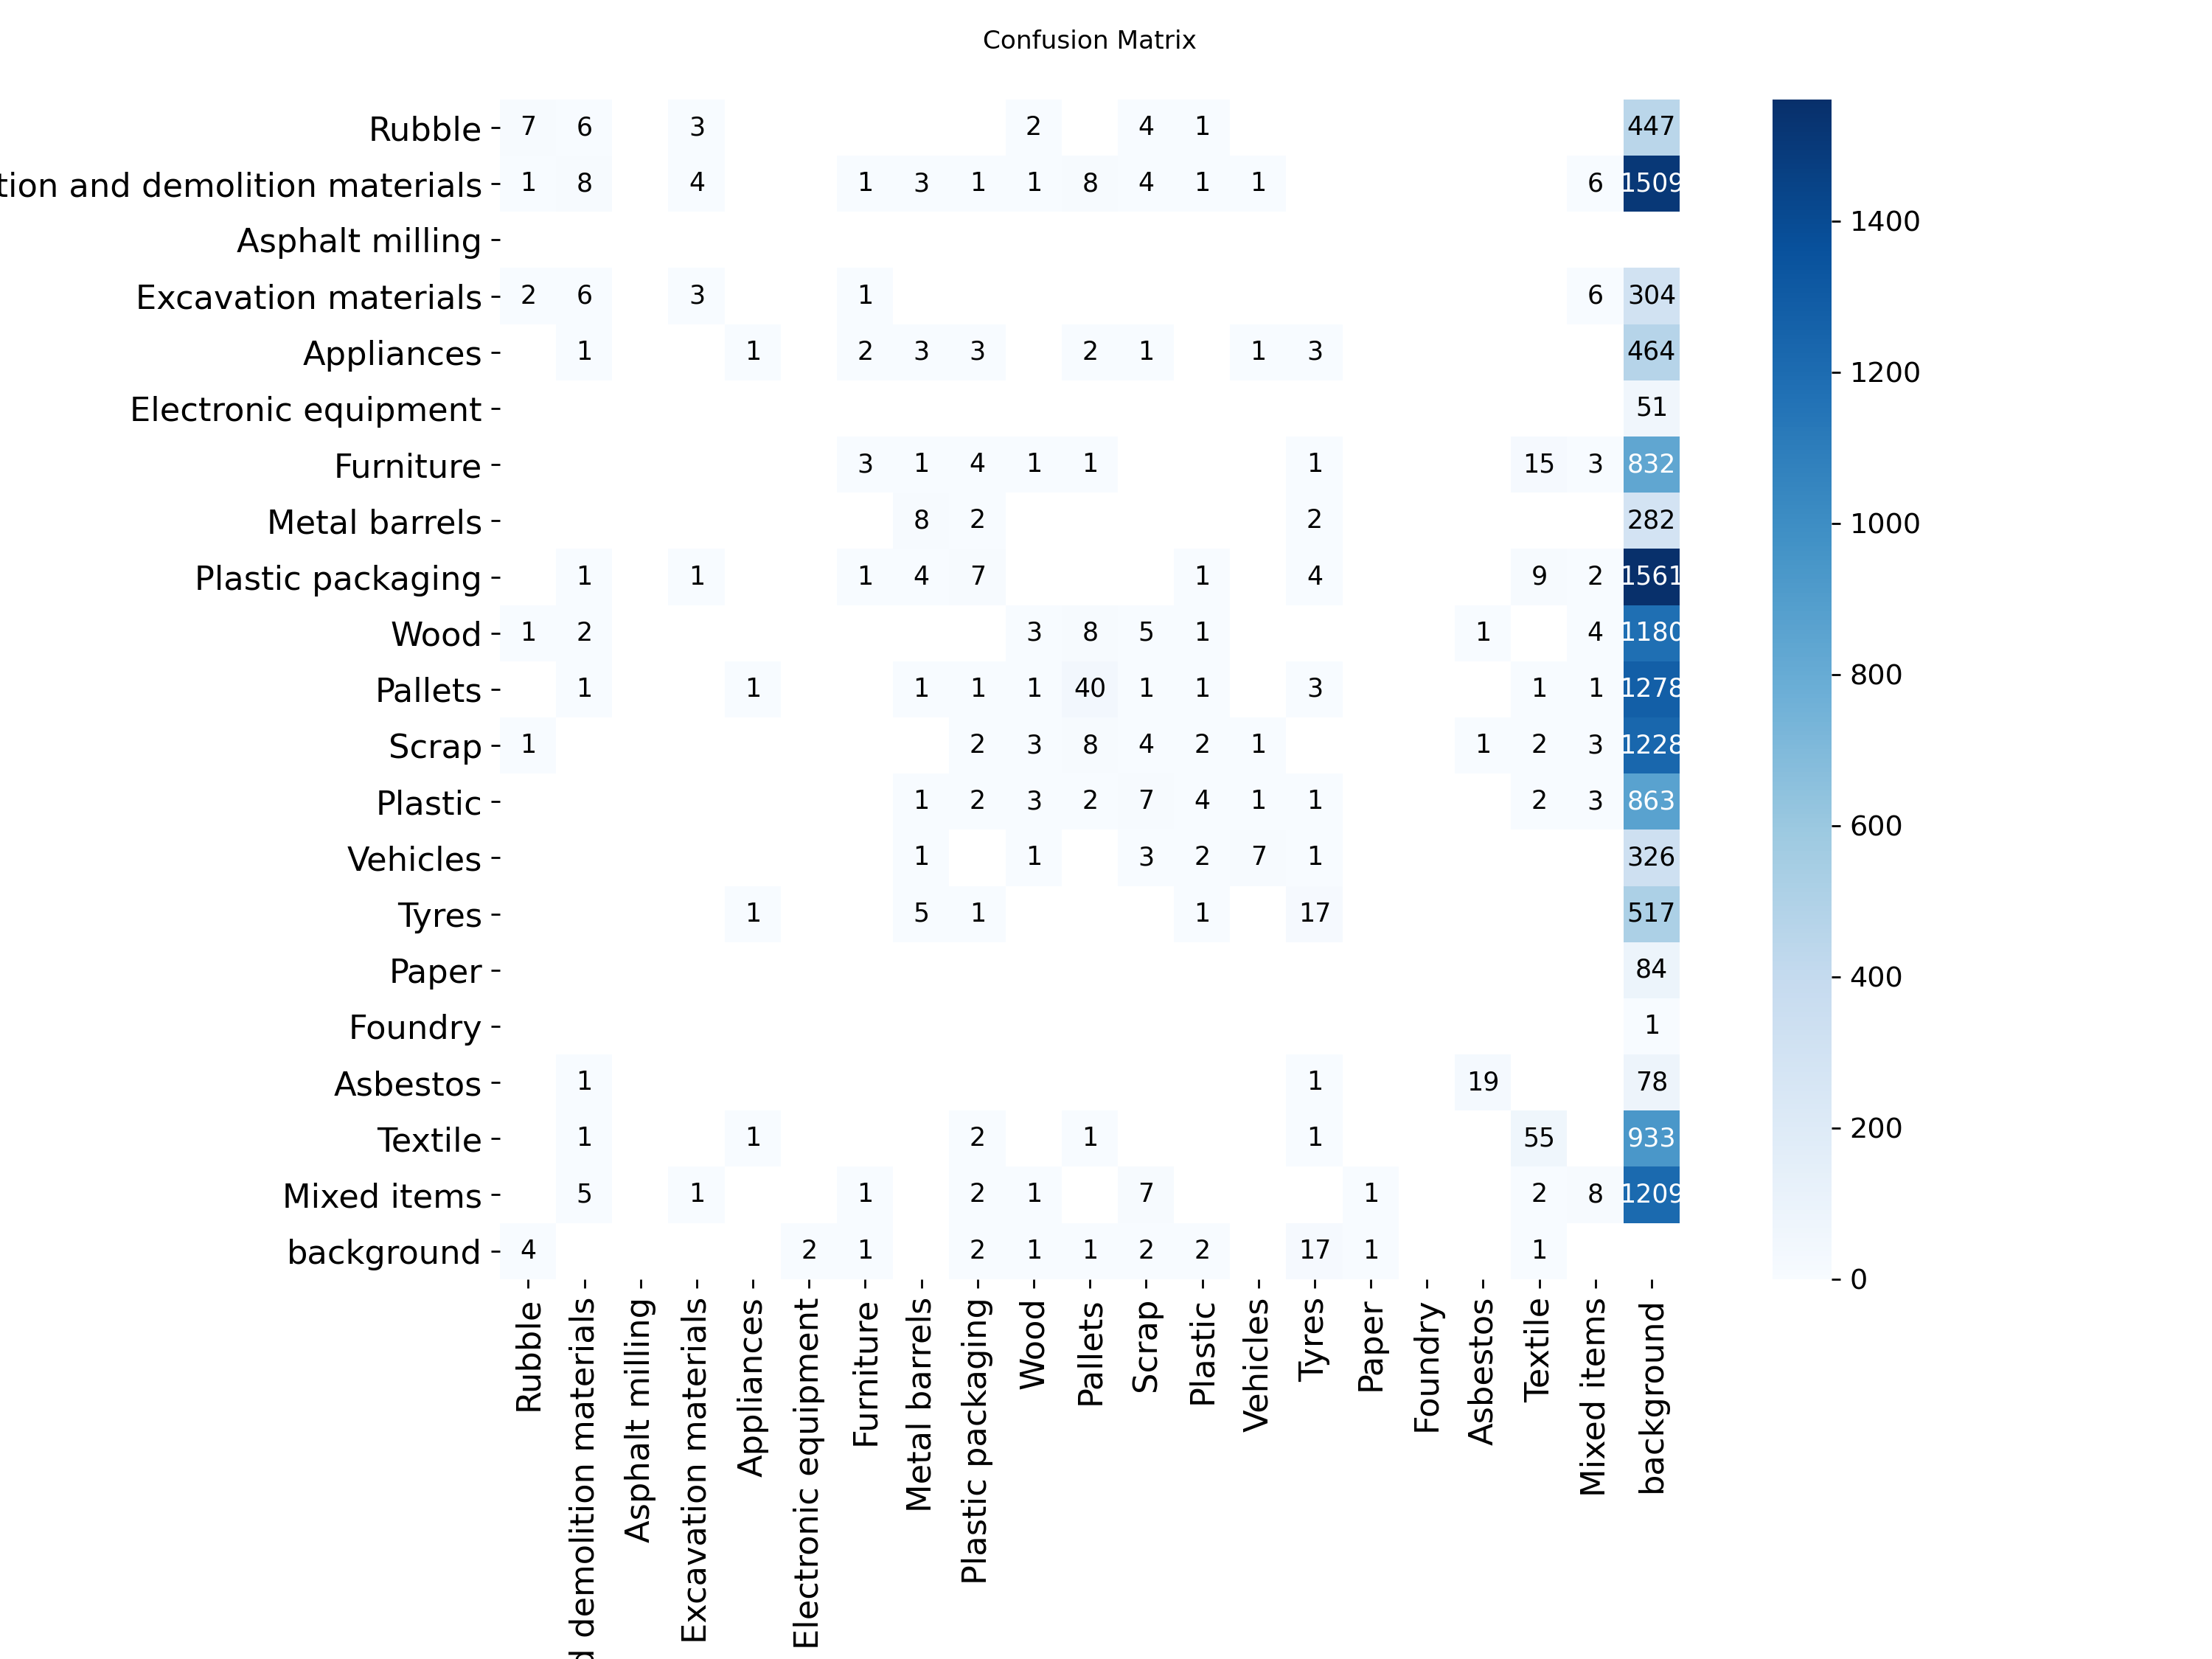


Saved: /content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/confusion_matrix/nano_fold01_val/confusion_matrix_normalized.png


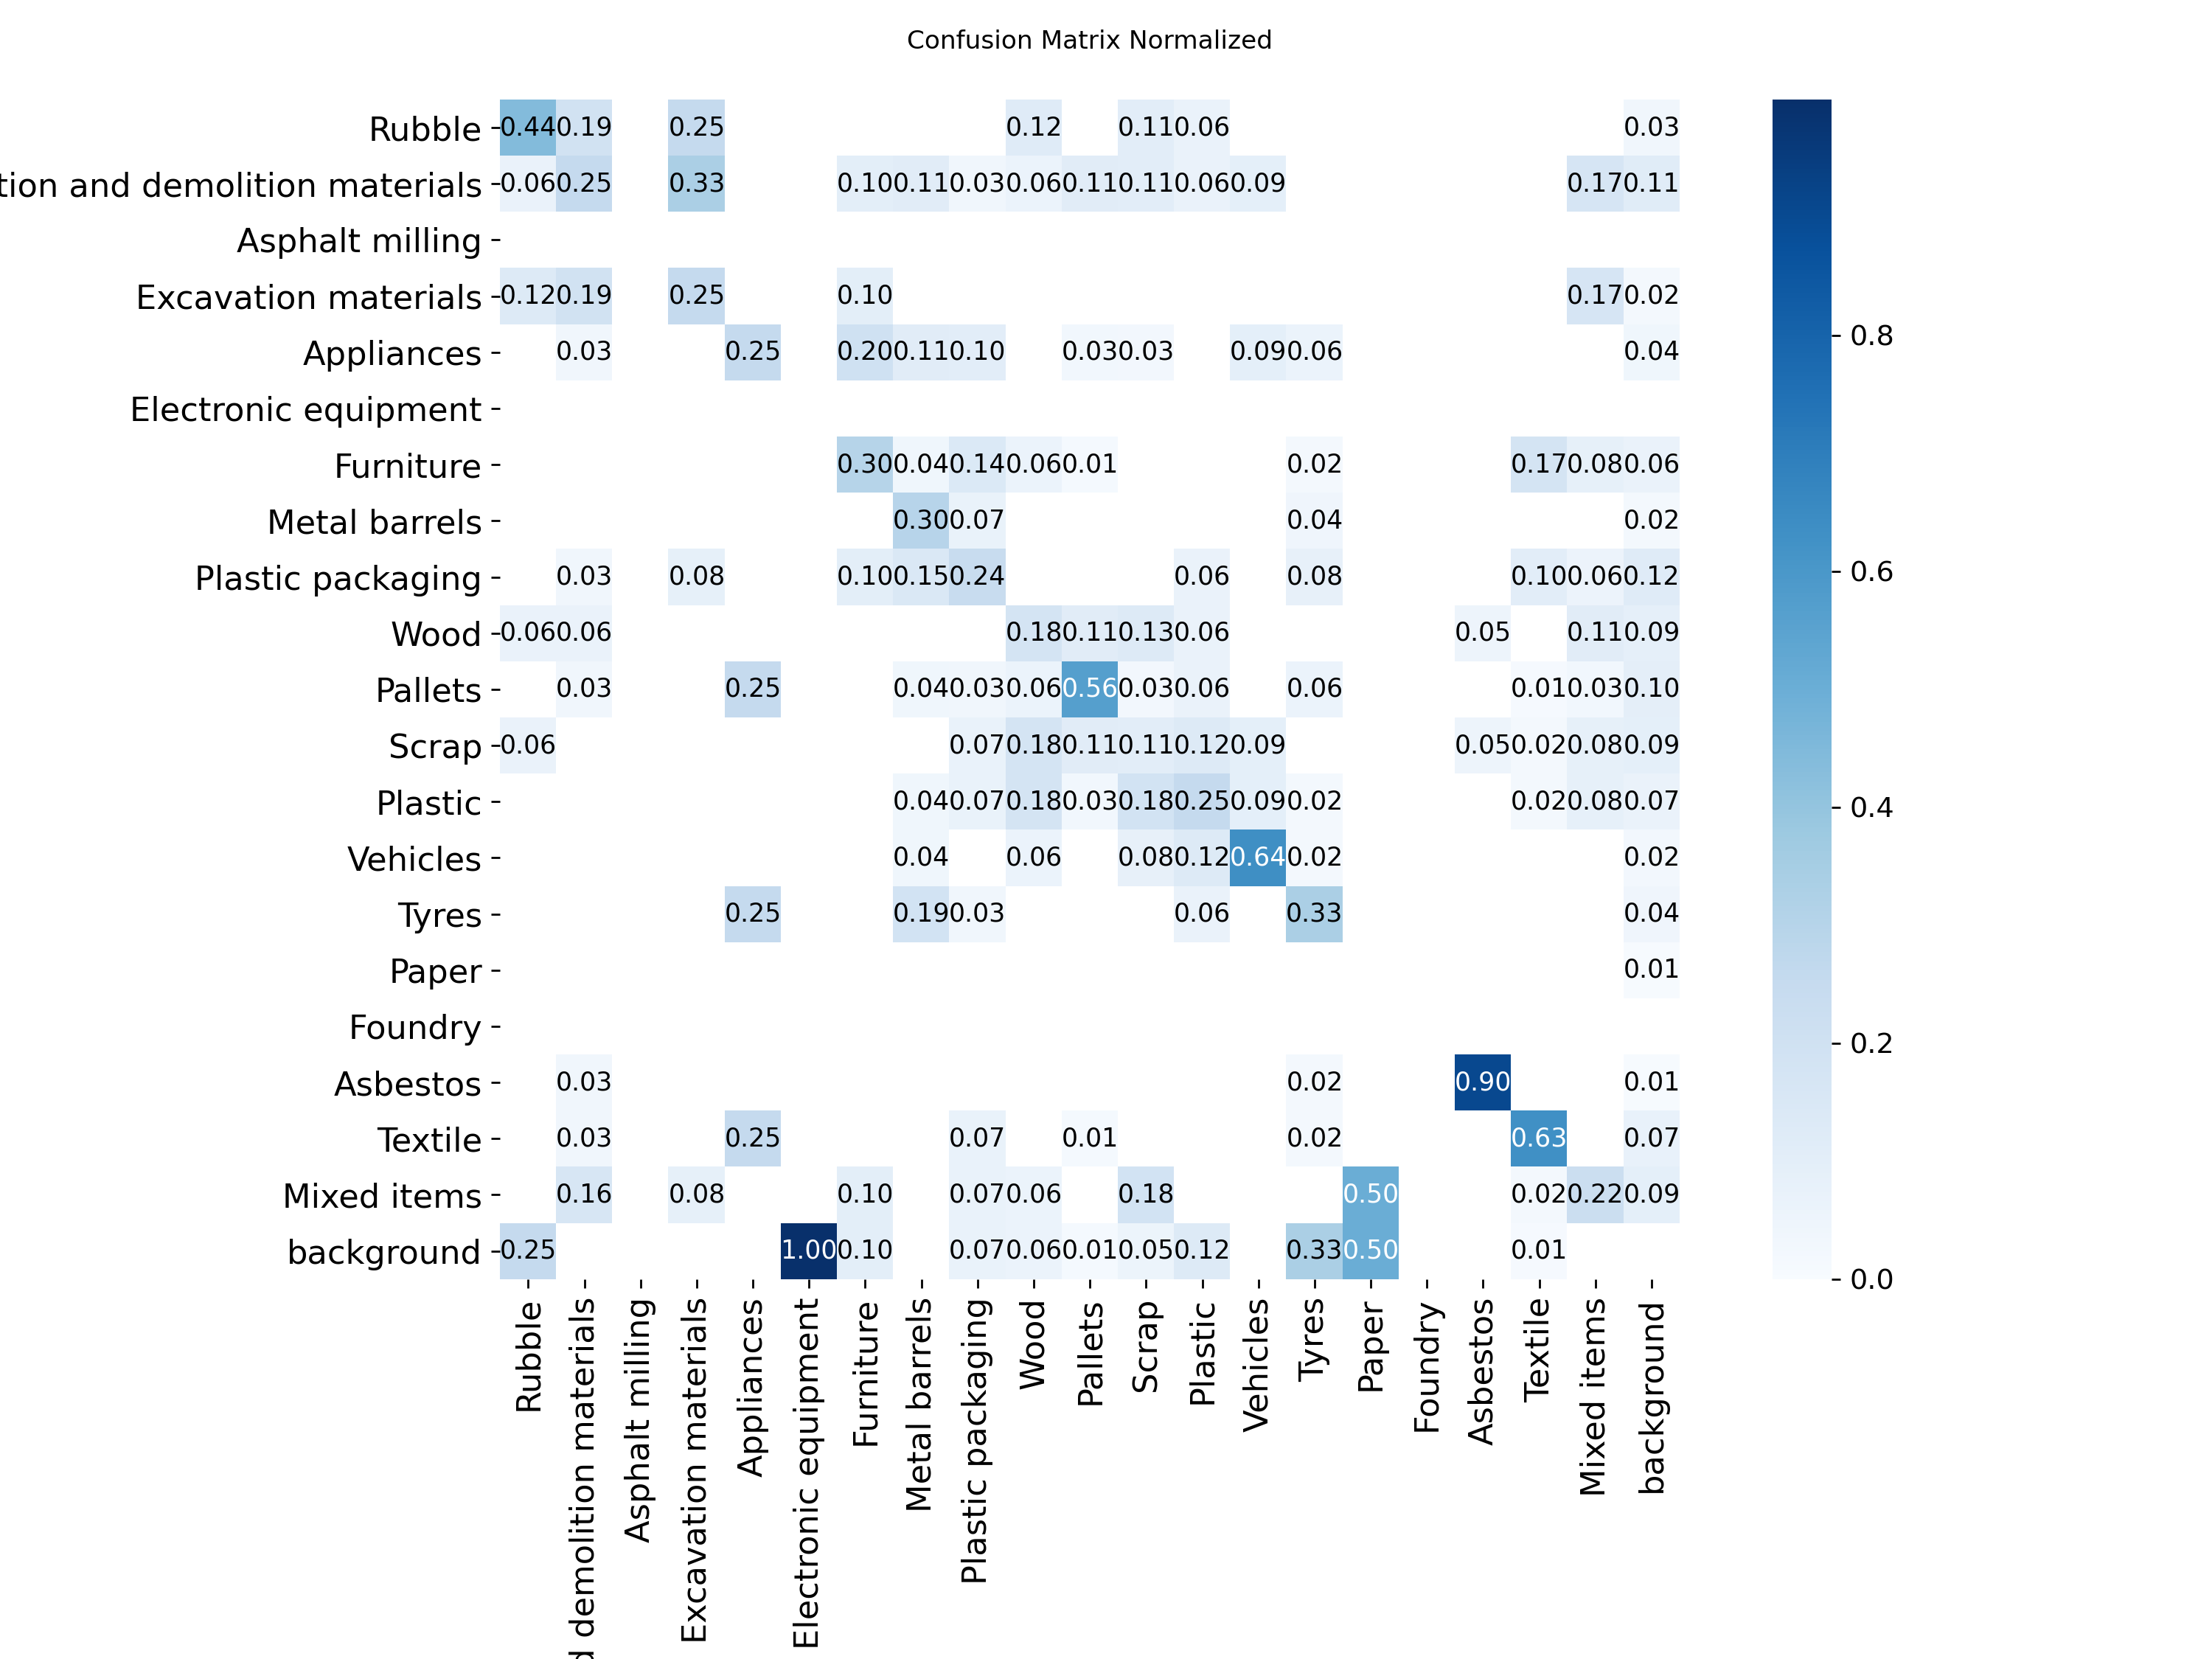

In [ ]:
from pathlib import Path
from ultralytics import YOLO
import yaml

# Paths
MODEL_PATH = Path(
    "/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/best.pt"
)

DATA_YAML = Path(
    "/content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/confusion_matrix"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verify required files
assert MODEL_PATH.exists(), f"Model not found: {MODEL_PATH}"
assert DATA_YAML.exists(), f"Dataset YAML not found: {DATA_YAML}"

# Load YOLOv12 Nano
model = YOLO(str(MODEL_PATH))

# Generate confusion matrix on validation split
metrics = model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640,
    batch=8,
    workers=2,
    device=0,
    plots=True,
    project=str(OUTPUT_DIR),
    name="nano_fold01_val",
    exist_ok=True
)

print("\nValidation confusion matrix generated.")
print("Results directory:", OUTPUT_DIR / "nano_fold01_val")

# Print validation metrics
print("\nValidation metrics:")
print(f"Precision:  {metrics.box.mp:.4f}")
print(f"Recall:     {metrics.box.mr:.4f}")
print(f"mAP50:      {metrics.box.map50:.4f}")
print(f"mAP50-95:   {metrics.box.map:.4f}")

# Locate and display the confusion matrix
run_dir = OUTPUT_DIR / "nano_fold01_val"

for filename in ["confusion_matrix.png", "confusion_matrix_normalized.png"]:
    image_path = run_dir / filename
    if image_path.exists():
        print(f"\nSaved: {image_path}")
        try:
            from IPython.display import display, Image
            display(Image(filename=str(image_path)))
        except Exception as e:
            print("Could not display image:", e)

In [ ]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/DroneWaste")

checks = {
    "Original image archive": ROOT / "images.tar.gz",
    "Original COCO annotations": ROOT / "dronewaste_v1.0.json",
    "Converted YOLO labels": ROOT / "yolo_labels",
    "YOLO class mapping": ROOT / "yolo_class_mapping.json",
    "17-fold CV manifests": ROOT / "official_style_cv_manifests.json",
    "Dataset metadata": ROOT / "yolo_dataset_metadata.json",
    "Nano best checkpoint": ROOT / "results/fold_01/yolo12n/best.pt",
    "Nano training metrics": ROOT / "results/fold_01/yolo12n/results.csv",
    "Nano training summary": ROOT / "results/fold_01/yolo12n/training_summary.json",
}

print("DRONEWASTE DRIVE VERIFICATION")
print("=" * 55)

all_ok = True

for name, path in checks.items():
    exists = path.exists()
    print(f"{'✅' if exists else '❌'} {name}: {exists}")
    if not exists:
        all_ok = False

# Count converted label files
labels_dir = ROOT / "yolo_labels"
if labels_dir.exists():
    label_files = list(labels_dir.glob("*.txt"))
    print(f"\nYOLO label files found: {len(label_files)}")
    print("Expected: 4993")
    if len(label_files) != 4993:
        all_ok = False

# Inspect fold manifest
manifest_path = ROOT / "official_style_cv_manifests.json"
if manifest_path.exists():
    with open(manifest_path, "r") as f:
        manifests = json.load(f)

    print("\nManifest loaded successfully.")
    print("Manifest structure:", type(manifests).__name__)

# Inspect class mapping
mapping_path = ROOT / "yolo_class_mapping.json"
if mapping_path.exists():
    with open(mapping_path, "r") as f:
        mapping = json.load(f)

    print("Class mapping loaded successfully.")

print("\nOVERALL:", "FILES PRESENT" if all_ok else "MISSING ITEMS — FIX BEFORE TRAINING")

DRONEWASTE DRIVE VERIFICATION
✅ Original image archive: True
✅ Original COCO annotations: True
✅ Converted YOLO labels: True
✅ YOLO class mapping: True
✅ 17-fold CV manifests: True
✅ Dataset metadata: True
✅ Nano best checkpoint: True
✅ Nano training metrics: True
✅ Nano training summary: True

YOLO label files found: 4993
Expected: 4993

Manifest loaded successfully.
Manifest structure: dict
Class mapping loaded successfully.

OVERALL: FILES PRESENT


## 9. YOLOv12 Small — Fold 1 training and validation

Verify the environment and dataset, train the Small model, and inspect its saved checkpoint and validation outputs.

In [ ]:
from pathlib import Path
import torch
import yaml
import json

ROOT = Path("/content/drive/MyDrive/DroneWaste")
WORK = Path("/content/dronewaste_work")

IMAGES_DIR = WORK / "images"
FOLD_DIR = WORK / "yolo_folds/fold_01"
DATA_YAML = FOLD_DIR / "dronewaste_fold01.yaml"

print("=" * 55)
print("YOLOv12 SMALL — PRE-TRAINING ENVIRONMENT CHECK")
print("=" * 55)

# 1. GPU
print("\n1. GPU")
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Extracted images
print("\n2. Extracted images")
print("Images directory exists:", IMAGES_DIR.exists())
if IMAGES_DIR.exists():
    image_count = sum(
        1 for p in IMAGES_DIR.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    )
    print("Image files found:", image_count)

# 3. Fold 1 YAML
print("\n3. Fold 1 dataset YAML")
print("YAML exists:", DATA_YAML.exists())

if DATA_YAML.exists():
    with open(DATA_YAML, "r") as f:
        config = yaml.safe_load(f)

    print("Dataset configuration:")
    print(json.dumps(config, indent=2))

# 4. Nano checkpoint remains safe
nano_best = ROOT / "results/fold_01/yolo12n/best.pt"
print("\n4. Nano checkpoint")
print("Exists:", nano_best.exists())
if nano_best.exists():
    print(f"Size: {nano_best.stat().st_size / (1024**2):.2f} MB")

print("\n" + "=" * 55)
print("CHECK COMPLETE — review output before proceeding")

YOLOv12 SMALL — PRE-TRAINING ENVIRONMENT CHECK

1. GPU
CUDA available: True
GPU: Tesla T4

2. Extracted images
Images directory exists: False

3. Fold 1 dataset YAML
YAML exists: False

4. Nano checkpoint
Exists: True
Size: 5.31 MB

CHECK COMPLETE — review output before proceeding


In [ ]:
from pathlib import Path
import tarfile
import json
import yaml

ROOT = Path("/content/drive/MyDrive/DroneWaste")
WORK = Path("/content/dronewaste_work")

ARCHIVE = ROOT / "images.tar.gz"
MANIFEST_PATH = ROOT / "official_style_cv_manifests.json"
IMAGES_DIR = WORK / "images"
FOLD_DIR = WORK / "yolo_folds/fold_01"
DATA_YAML = FOLD_DIR / "dronewaste_fold01.yaml"

assert ARCHIVE.exists(), f"Missing archive: {ARCHIVE}"
assert MANIFEST_PATH.exists(), f"Missing manifests: {MANIFEST_PATH}"

WORK.mkdir(parents=True, exist_ok=True)

# 1. Extract images
# Extract only if the expected image directory is not already populated.
if not IMAGES_DIR.exists() or not any(IMAGES_DIR.rglob("*")):
    IMAGES_DIR.mkdir(parents=True, exist_ok=True)
    print("Extracting image archive...")

    with tarfile.open(ARCHIVE, "r:gz") as tar:
        # Prevent archive paths from escaping the extraction directory.
        base = IMAGES_DIR.resolve()
        for member in tar.getmembers():
            target = (IMAGES_DIR / member.name).resolve()
            if target != base and base not in target.parents:
                raise RuntimeError(
                    f"Unsafe archive path detected: {member.name}"
                )
        tar.extractall(IMAGES_DIR)

    print("Extraction finished.")
else:
    print("Image directory already contains files; skipping extraction.")

# 2. Locate image files
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths = [
    p for p in IMAGES_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]
print("Image files found:", len(image_paths))

assert len(image_paths) == 4993, (
    f"Expected 4993 images, found {len(image_paths)}. "
    "Stop and inspect the archive layout before training."
)

# 3. Load and inspect the official-style Fold 1 manifest
with open(MANIFEST_PATH, "r") as f:
    manifests = json.load(f)

print("Manifest top-level keys:", list(manifests.keys()))

# Do not guess the manifest schema. Inspect its structure first.
print("\nManifest preview:")
print(json.dumps(manifests, indent=2)[:4000])

print(
    "\nImages restored. Review the manifest preview above before "
    "creating the YAML."
)

Extracting image archive...


/tmp/ipykernel_1424/4047283163.py:35: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(IMAGES_DIR)


Extraction finished.
Image files found: 4993
Manifest top-level keys: ['protocol', 'random_seed', 'validation_fraction', 'number_of_folds', 'folds']

Manifest preview:
{
  "protocol": "Leave-one-site-out; iterative multilabel stratified 10% validation",
  "random_seed": 1337,
  "validation_fraction": 0.1,
  "number_of_folds": 17,
  "folds": [
    {
      "fold": 1,
      "test_site": "site1",
      "random_seed": 1337,
      "validation_fraction": 0.1,
      "train_images": [
        "site10_10.png",
        "site10_11.png",
        "site10_12.png",
        "site10_13.png",
        "site10_17.png",
        "site10_18.png",
        "site10_19.png",
        "site10_2.png",
        "site10_20.png",
        "site10_21.png",
        "site10_22.png",
        "site10_27.png",
        "site10_28.png",
        "site10_29.png",
        "site10_30.png",
        "site10_51.png",
        "site10_9.png",
        "site11_10.png",
        "site11_105.png",
        "site11_106.png",
        "site11_107

In [ ]:
from pathlib import Path

WORK = Path("/content/dronewaste_work")
ROOT = Path("/content/drive/MyDrive/DroneWaste")

print("Searching temporary workspace...")
for p in WORK.rglob("*"):
    if p.is_file() and p.suffix.lower() in {".png", ".jpg", ".jpeg"}:
        print("First image found:", p)
        break
else:
    print("No images found in workspace.")

print("\nChecking common extraction layouts...")
for base in [WORK / "images", WORK, ROOT]:
    print(f"\nDirectory: {base}")
    print("Exists:", base.exists())

    if base.exists():
        matches = list(base.rglob("site6_983.png"))
        print("Matching site6_983.png:", matches[:5])

        if base == ROOT:
            print("Top-level entries:", [x.name for x in list(base.iterdir())[:15]])

Searching temporary workspace...
First image found: /content/dronewaste_work/images/images/site1_67.png

Checking common extraction layouts...

Directory: /content/dronewaste_work/images
Exists: True
Matching site6_983.png: [PosixPath('/content/dronewaste_work/images/images/site6_983.png')]

Directory: /content/dronewaste_work
Exists: True
Matching site6_983.png: [PosixPath('/content/dronewaste_work/images/images/site6_983.png')]

Directory: /content/drive/MyDrive/DroneWaste
Exists: True
Matching site6_983.png: []
Top-level entries: ['dronewaste_v1.0.json', 'images.tar.gz', 'yolo_labels', 'yolo_class_mapping.json', 'sitewise_cv_plan.json', 'official_style_cv_manifests.json', 'yolo_dataset_metadata.json', 'experiment_config.json', 'results']


In [ ]:
import json
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/DroneWaste/yolo_class_mapping.json"
)

with open(path, "r") as f:
    mapping = json.load(f)

print("Mapping type:", type(mapping).__name__)
print("Mapping contents:")
print(json.dumps(mapping, indent=2)[:5000])

Mapping type: dict
Mapping contents:
{
  "names": [
    "Rubble",
    "Construction and demolition materials",
    "Asphalt milling",
    "Excavation materials",
    "Appliances",
    "Electronic equipment",
    "Furniture",
    "Metal barrels",
    "Plastic packaging",
    "Wood",
    "Pallets",
    "Scrap",
    "Plastic",
    "Vehicles",
    "Tyres",
    "Paper",
    "Foundry",
    "Asbestos",
    "Textile",
    "Mixed items"
  ],
  "coco_category_id_to_yolo_class_id": {
    "1": 0,
    "2": 1,
    "3": 2,
    "4": 3,
    "5": 4,
    "6": 5,
    "7": 6,
    "8": 7,
    "9": 8,
    "10": 9,
    "11": 10,
    "12": 11,
    "13": 12,
    "14": 13,
    "15": 14,
    "16": 15,
    "17": 16,
    "18": 17,
    "19": 18,
    "20": 19
  },
  "image_count": 4993,
  "annotation_count": 5135,
  "empty_label_count": 3822
}


In [ ]:
from pathlib import Path
import json
import yaml

ROOT = Path("/content/drive/MyDrive/DroneWaste")
WORK = Path("/content/dronewaste_work")

IMAGES_DIR = WORK / "images" / "images"
LABELS_DIR = ROOT / "yolo_labels"
FOLD_DIR = WORK / "yolo_folds" / "fold_01"
DATASET_DIR = FOLD_DIR / "dataset"
DATA_YAML = FOLD_DIR / "dronewaste_fold01.yaml"

# Load the actual class mapping structure
with open(ROOT / "yolo_class_mapping.json", "r") as f:
    mapping = json.load(f)

class_names = mapping["names"]
assert len(class_names) == 20, f"Expected 20 classes, got {len(class_names)}"

# Confirm the split directories were created by the previous cell
for split, expected in [("train", 4386), ("val", 488), ("test", 119)]:
    image_dir = DATASET_DIR / "images" / split
    label_dir = DATASET_DIR / "labels" / split

    assert image_dir.exists(), f"Missing {image_dir}"
    assert label_dir.exists(), f"Missing {label_dir}"
    assert len(list(image_dir.iterdir())) == expected, f"Wrong image count for {split}"
    assert len(list(label_dir.iterdir())) == expected, f"Wrong label count for {split}"

# Create Ultralytics-compatible YAML
config = {
    "path": str(DATASET_DIR),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {i: name for i, name in enumerate(class_names)},
    "nc": len(class_names),
}

FOLD_DIR.mkdir(parents=True, exist_ok=True)
with open(DATA_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

# Read back and verify
with open(DATA_YAML, "r") as f:
    verified = yaml.safe_load(f)

assert verified["nc"] == 20
assert verified["names"][0] == "Rubble"
assert verified["names"][19] == "Mixed items"

print("SUCCESS — Fold 1 YAML created and verified.")
print("YAML:", DATA_YAML)
print("Classes:", verified["nc"])
print("Train: 4386 | Validation: 488 | Test: 119")
print("Held-out test site: site1")

SUCCESS — Fold 1 YAML created and verified.
YAML: /content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml
Classes: 20
Train: 4386 | Validation: 488 | Test: 119
Held-out test site: site1


In [ ]:
from pathlib import Path
import yaml
import torch
import ultralytics

ROOT = Path("/content/drive/MyDrive/DroneWaste")
WORK = Path("/content/dronewaste_work")

DATA_YAML = WORK / "yolo_folds/fold_01/dronewaste_fold01.yaml"
NANO_DIR = ROOT / "results/fold_01/yolo12n"
SMALL_DIR = ROOT / "results/fold_01/yolo12s"

# GPU check
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("GPU unavailable. In Colab, select Runtime > Change runtime type > T4 GPU.")

print("Ultralytics version:", ultralytics.__version__)

# YAML and dataset check
assert DATA_YAML.is_file(), f"Missing YAML: {DATA_YAML}"

with open(DATA_YAML, "r") as f:
    cfg = yaml.safe_load(f)

dataset_root = Path(cfg["path"])
for split, expected in [("train", 4386), ("val", 488), ("test", 119)]:
    image_dir = dataset_root / "images" / split
    label_dir = dataset_root / "labels" / split

    images = list(image_dir.iterdir())
    labels = list(label_dir.iterdir())

    assert len(images) == expected, f"{split}: expected {expected} images, found {len(images)}"
    assert len(labels) == expected, f"{split}: expected {expected} labels, found {len(labels)}"
    assert all(p.exists() for p in images), f"Broken image link in {split}"
    assert all(p.exists() for p in labels), f"Broken label link in {split}"

# Confirm Nano results remain safe on Drive
assert (NANO_DIR / "best.pt").is_file(), "Nano best.pt missing from Drive"
assert (NANO_DIR / "results.csv").is_file(), "Nano results.csv missing from Drive"

print("\nNano best.pt:", (NANO_DIR / "best.pt").stat().st_size // (1024 * 1024), "MB")
print("Small output directory already exists:", SMALL_DIR.exists())
print("\nPREFLIGHT PASSED — ready to train YOLOv12 Small.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
GPU available: True
GPU: Tesla T4
Ultralytics version: 8.4.178

Nano best.pt: 5 MB
Small output directory already exists: False

PREFLIGHT PASSED — ready to train YOLOv12 Small.


In [ ]:
from pathlib import Path
import json
import time
import torch
from ultralytics import YOLO

ROOT = Path("/content/drive/MyDrive/DroneWaste")
DATA_YAML = Path(
    "/content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml"
)
SAVE_DIR = ROOT / "results" / "fold_01" / "yolo12s"

assert torch.cuda.is_available(), "GPU is unavailable."
assert DATA_YAML.is_file(), "Dataset YAML is missing."
assert not SAVE_DIR.exists(), (
    f"{SAVE_DIR} already exists. Check its contents before overwriting."
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("Dataset:", DATA_YAML)
print("Saving results to:", SAVE_DIR)
print("Starting YOLOv12 Small training...")

model = YOLO("yolo12s.pt")
start_time = time.time()

results = model.train(
    data=str(DATA_YAML),
    epochs=50,
    imgsz=640,
    batch=8,
    workers=2,
    seed=1337,
    patience=15,
    device=0,
    pretrained=True,
    project=str(ROOT / "results" / "fold_01"),
    name="yolo12s",
    exist_ok=False,
    save=True,
    save_period=5,
    plots=True,
    verbose=True,
)

elapsed_minutes = (time.time() - start_time) / 60

summary = {
    "model": "YOLOv12 Small",
    "fold": 1,
    "held_out_test_site": "site1",
    "epochs_requested": 50,
    "image_size": 640,
    "batch_size": 8,
    "seed": 1337,
    "patience": 15,
    "training_time_minutes": round(elapsed_minutes, 2),
    "results_directory": str(SAVE_DIR),
}

with open(SAVE_DIR / "training_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print(f"\nTraining finished in {elapsed_minutes:.1f} minutes.")
print("Results saved to:", SAVE_DIR)
print("Best checkpoint exists:", (SAVE_DIR / "weights" / "best.pt").is_file())
print("Results CSV exists:", (SAVE_DIR / "results.csv").is_file())

GPU: Tesla T4
Dataset: /content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml
Saving results to: /content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s
Starting YOLOv12 Small training...
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=

In [ ]:
from pathlib import Path
import json
import pandas as pd

SAVE_DIR = Path(
    "/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s"
)

required_files = {
    "Best checkpoint": SAVE_DIR / "weights" / "best.pt",
    "Last checkpoint": SAVE_DIR / "weights" / "last.pt",
    "Training metrics CSV": SAVE_DIR / "results.csv",
    "Training plots": SAVE_DIR / "results.png",
}

print("YOLOv12 Small save verification\n")

for name, path in required_files.items():
    exists = path.is_file()
    size_mb = path.stat().st_size / (1024 * 1024) if exists else 0
    print(f"{name}: {'SAVED' if exists else 'NOT FOUND'}"
          f"{f' ({size_mb:.2f} MB)' if exists else ''}")

summary_path = SAVE_DIR / "training_summary.json"
print("Training summary:", "SAVED" if summary_path.is_file() else "NOT FOUND")

if (SAVE_DIR / "results.csv").is_file():
    df = pd.read_csv(SAVE_DIR / "results.csv")
    print("\nEpochs recorded:", len(df))
    print("Last recorded epoch:", df["epoch"].iloc[-1] if "epoch" in df.columns else "Check CSV")
    print("Available metric columns:")
    print([c for c in df.columns if "metrics/" in c or "fitness" in c])

YOLOv12 Small save verification

Best checkpoint: NOT FOUND
Last checkpoint: NOT FOUND
Training metrics CSV: NOT FOUND
Training plots: NOT FOUND
Training summary: SAVED


In [ ]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/DroneWaste")
SEARCH_DIRS = [
    ROOT / "results",
    Path("/content/runs"),
    Path("/content/dronewaste_work"),
]

targets = {"best.pt", "last.pt", "results.csv", "training_summary.json"}

for folder in SEARCH_DIRS:
    print(f"\n--- Searching: {folder} ---")
    if not folder.exists():
        print("Directory does not exist.")
        continue

    found = [
        p for p in folder.rglob("*")
        if p.is_file()
        and (p.name in targets or "yolo12s" in str(p).lower())
    ]

    if found:
        for p in found[:100]:
            print(f"{p}  ({p.stat().st_size / (1024 * 1024):.2f} MB)")
    else:
        print("No matching files found.")


--- Searching: /content/drive/MyDrive/DroneWaste/results ---
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/results.csv  (0.01 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/last.pt  (5.31 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/best.pt  (5.31 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/training_summary.json  (0.00 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s/training_summary.json  (0.00 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/args.yaml  (0.00 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/labels.jpg  (0.17 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/train_batch0.jpg  (0.57 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/train_batch1.jpg  (0.89 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/train_batch2.jpg  (0.61 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/results.csv  (0.01 MB)
/content/dr

In [ ]:
from pathlib import Path
import pandas as pd
import json

RUN_DIR = Path(
    "/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2"
)

best_pt = RUN_DIR / "weights" / "best.pt"
last_pt = RUN_DIR / "weights" / "last.pt"
csv_path = RUN_DIR / "results.csv"

for p in [best_pt, last_pt, csv_path]:
    assert p.is_file(), f"Missing file: {p}"
    print(f"FOUND: {p.name} ({p.stat().st_size / 1024**2:.2f} MB)")

df = pd.read_csv(csv_path)

print("\nRecorded epochs:", len(df))
if "epoch" in df.columns:
    print("Last recorded epoch:", df["epoch"].iloc[-1])

metric_cols = [
    c for c in df.columns
    if any(k in c.lower() for k in ["precision", "recall", "map50", "map50-95"])
]

print("\nLast recorded validation metrics:")
print(df[metric_cols].tail(1).to_string(index=False))

summary_path = RUN_DIR / "args.yaml"
print("\nTraining arguments saved:", summary_path.is_file())

FOUND: best.pt (18.07 MB)
FOUND: last.pt (18.07 MB)
FOUND: results.csv (0.01 MB)

Recorded epochs: 50
Last recorded epoch: 50

Last recorded validation metrics:
 metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
              0.57473            0.42725           0.42071              0.29946

Training arguments saved: True


confusion_matrix.png


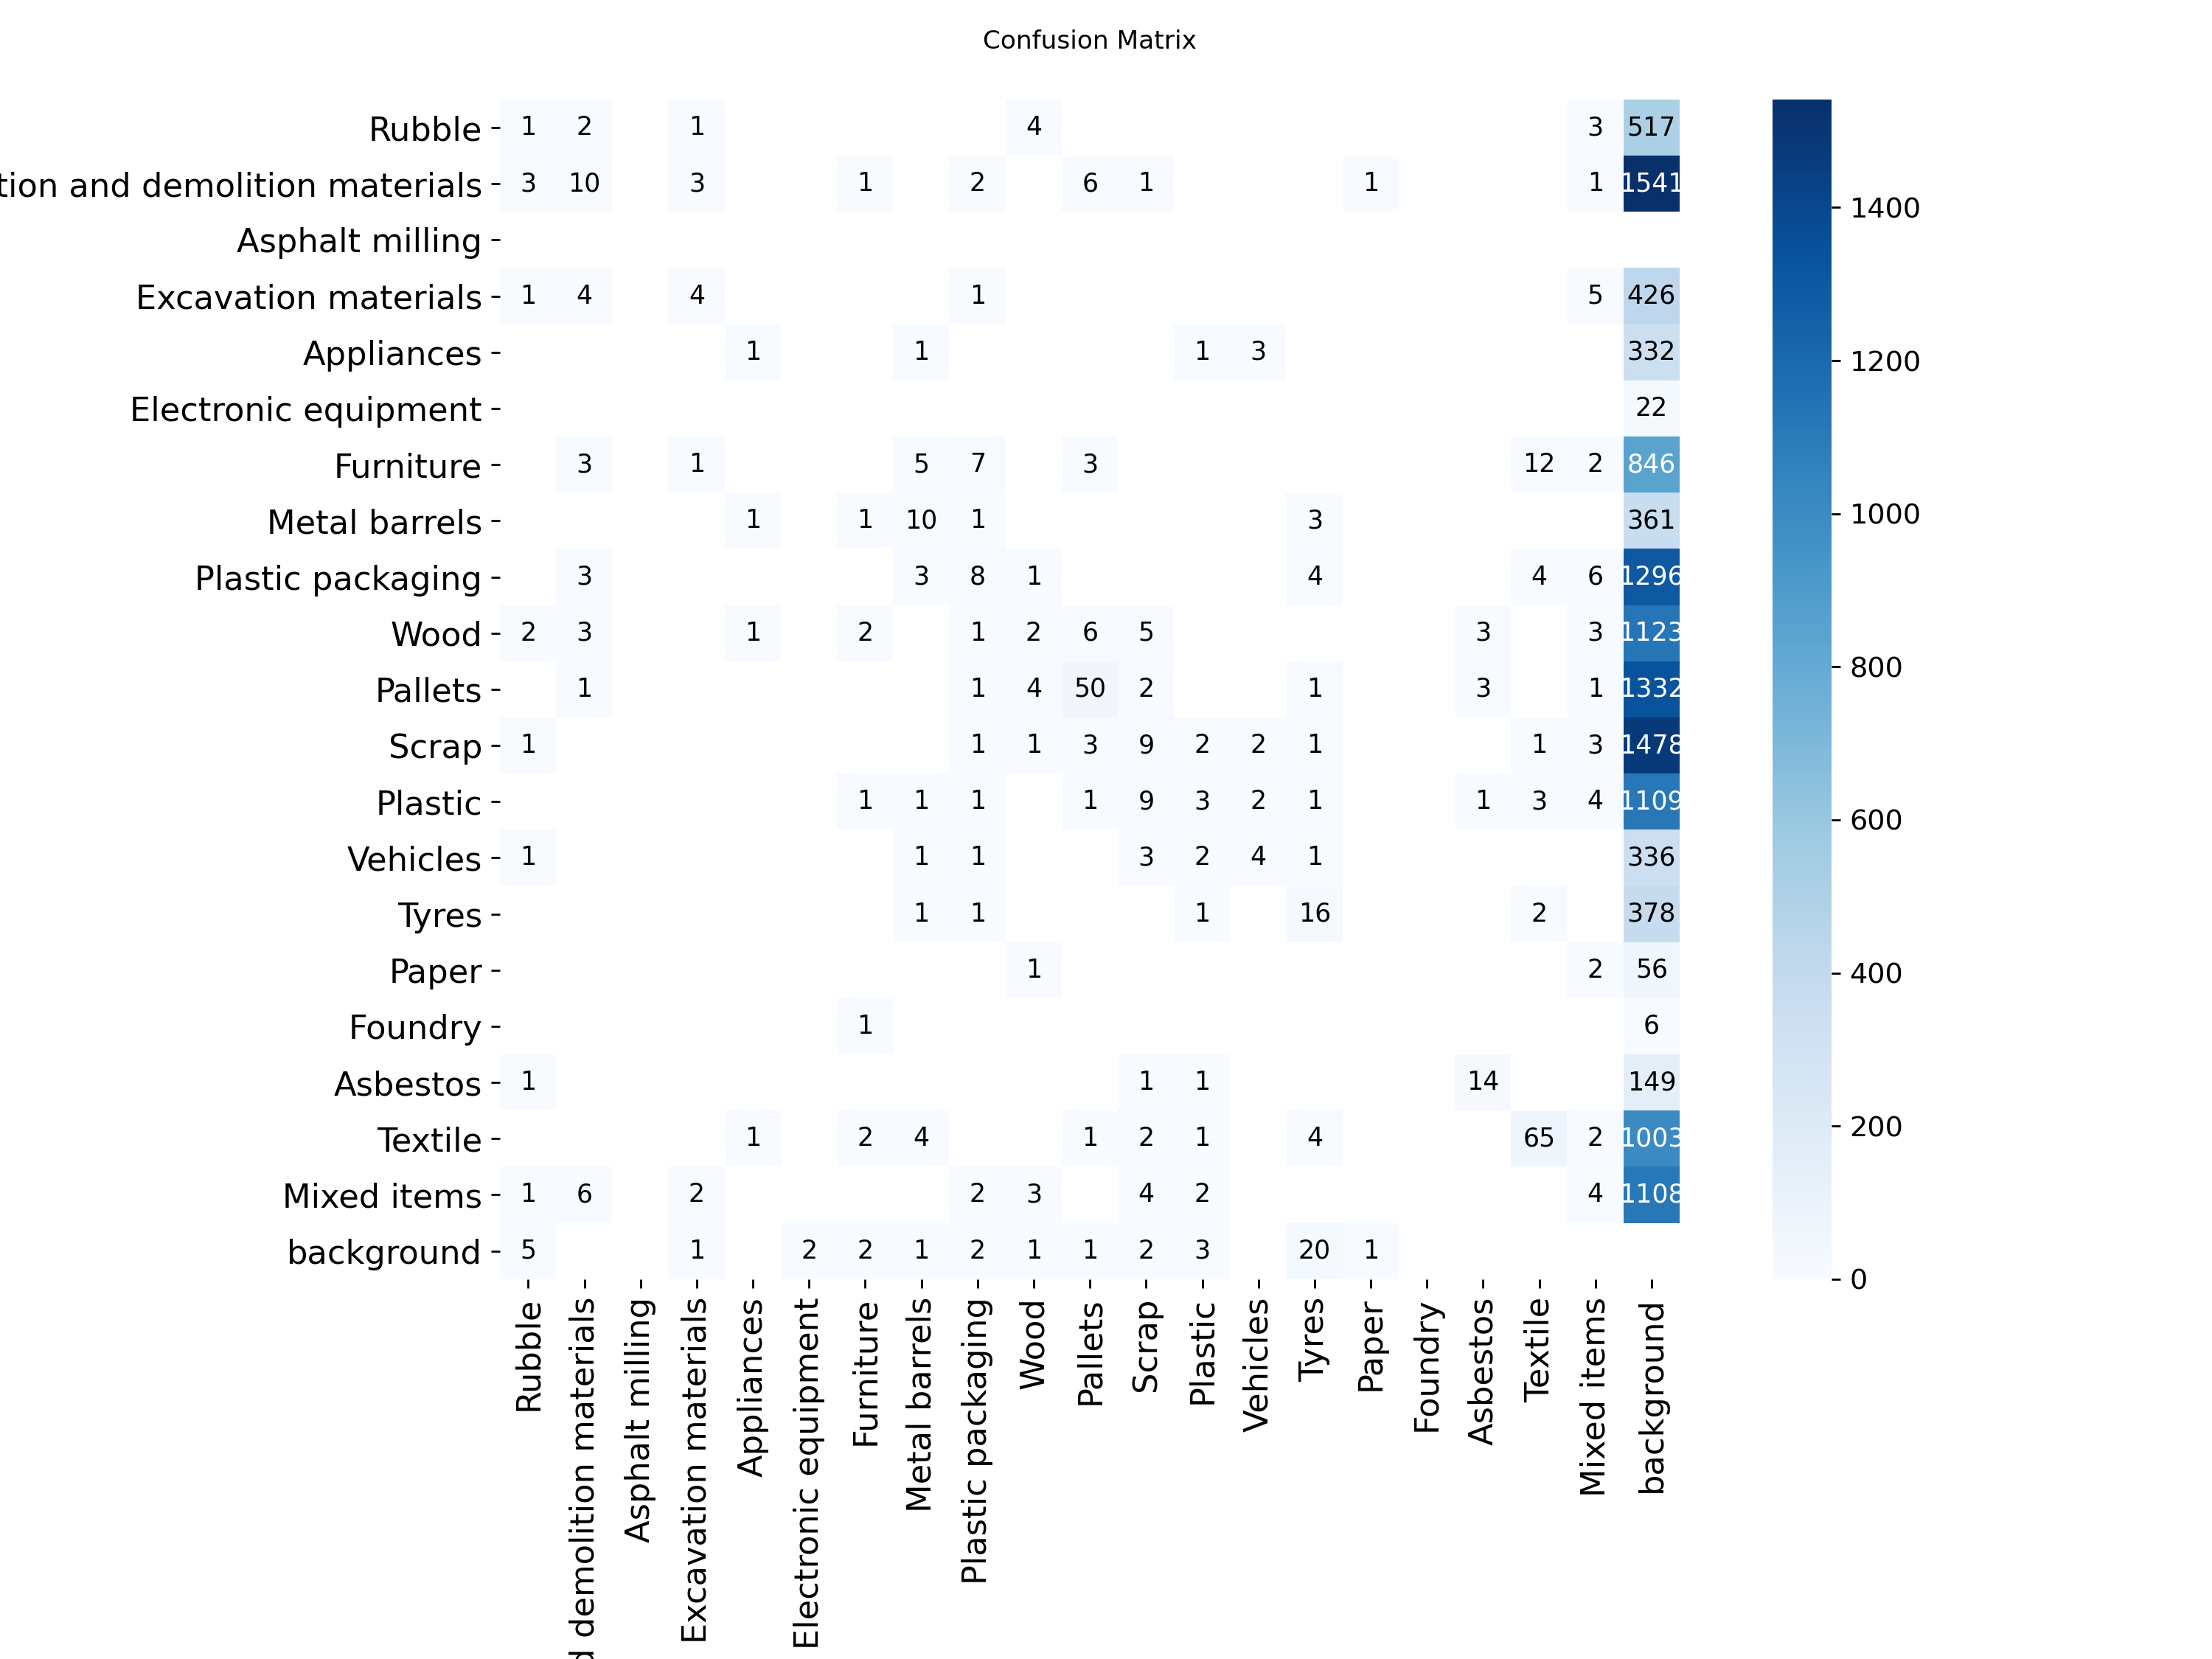

confusion_matrix_normalized.png


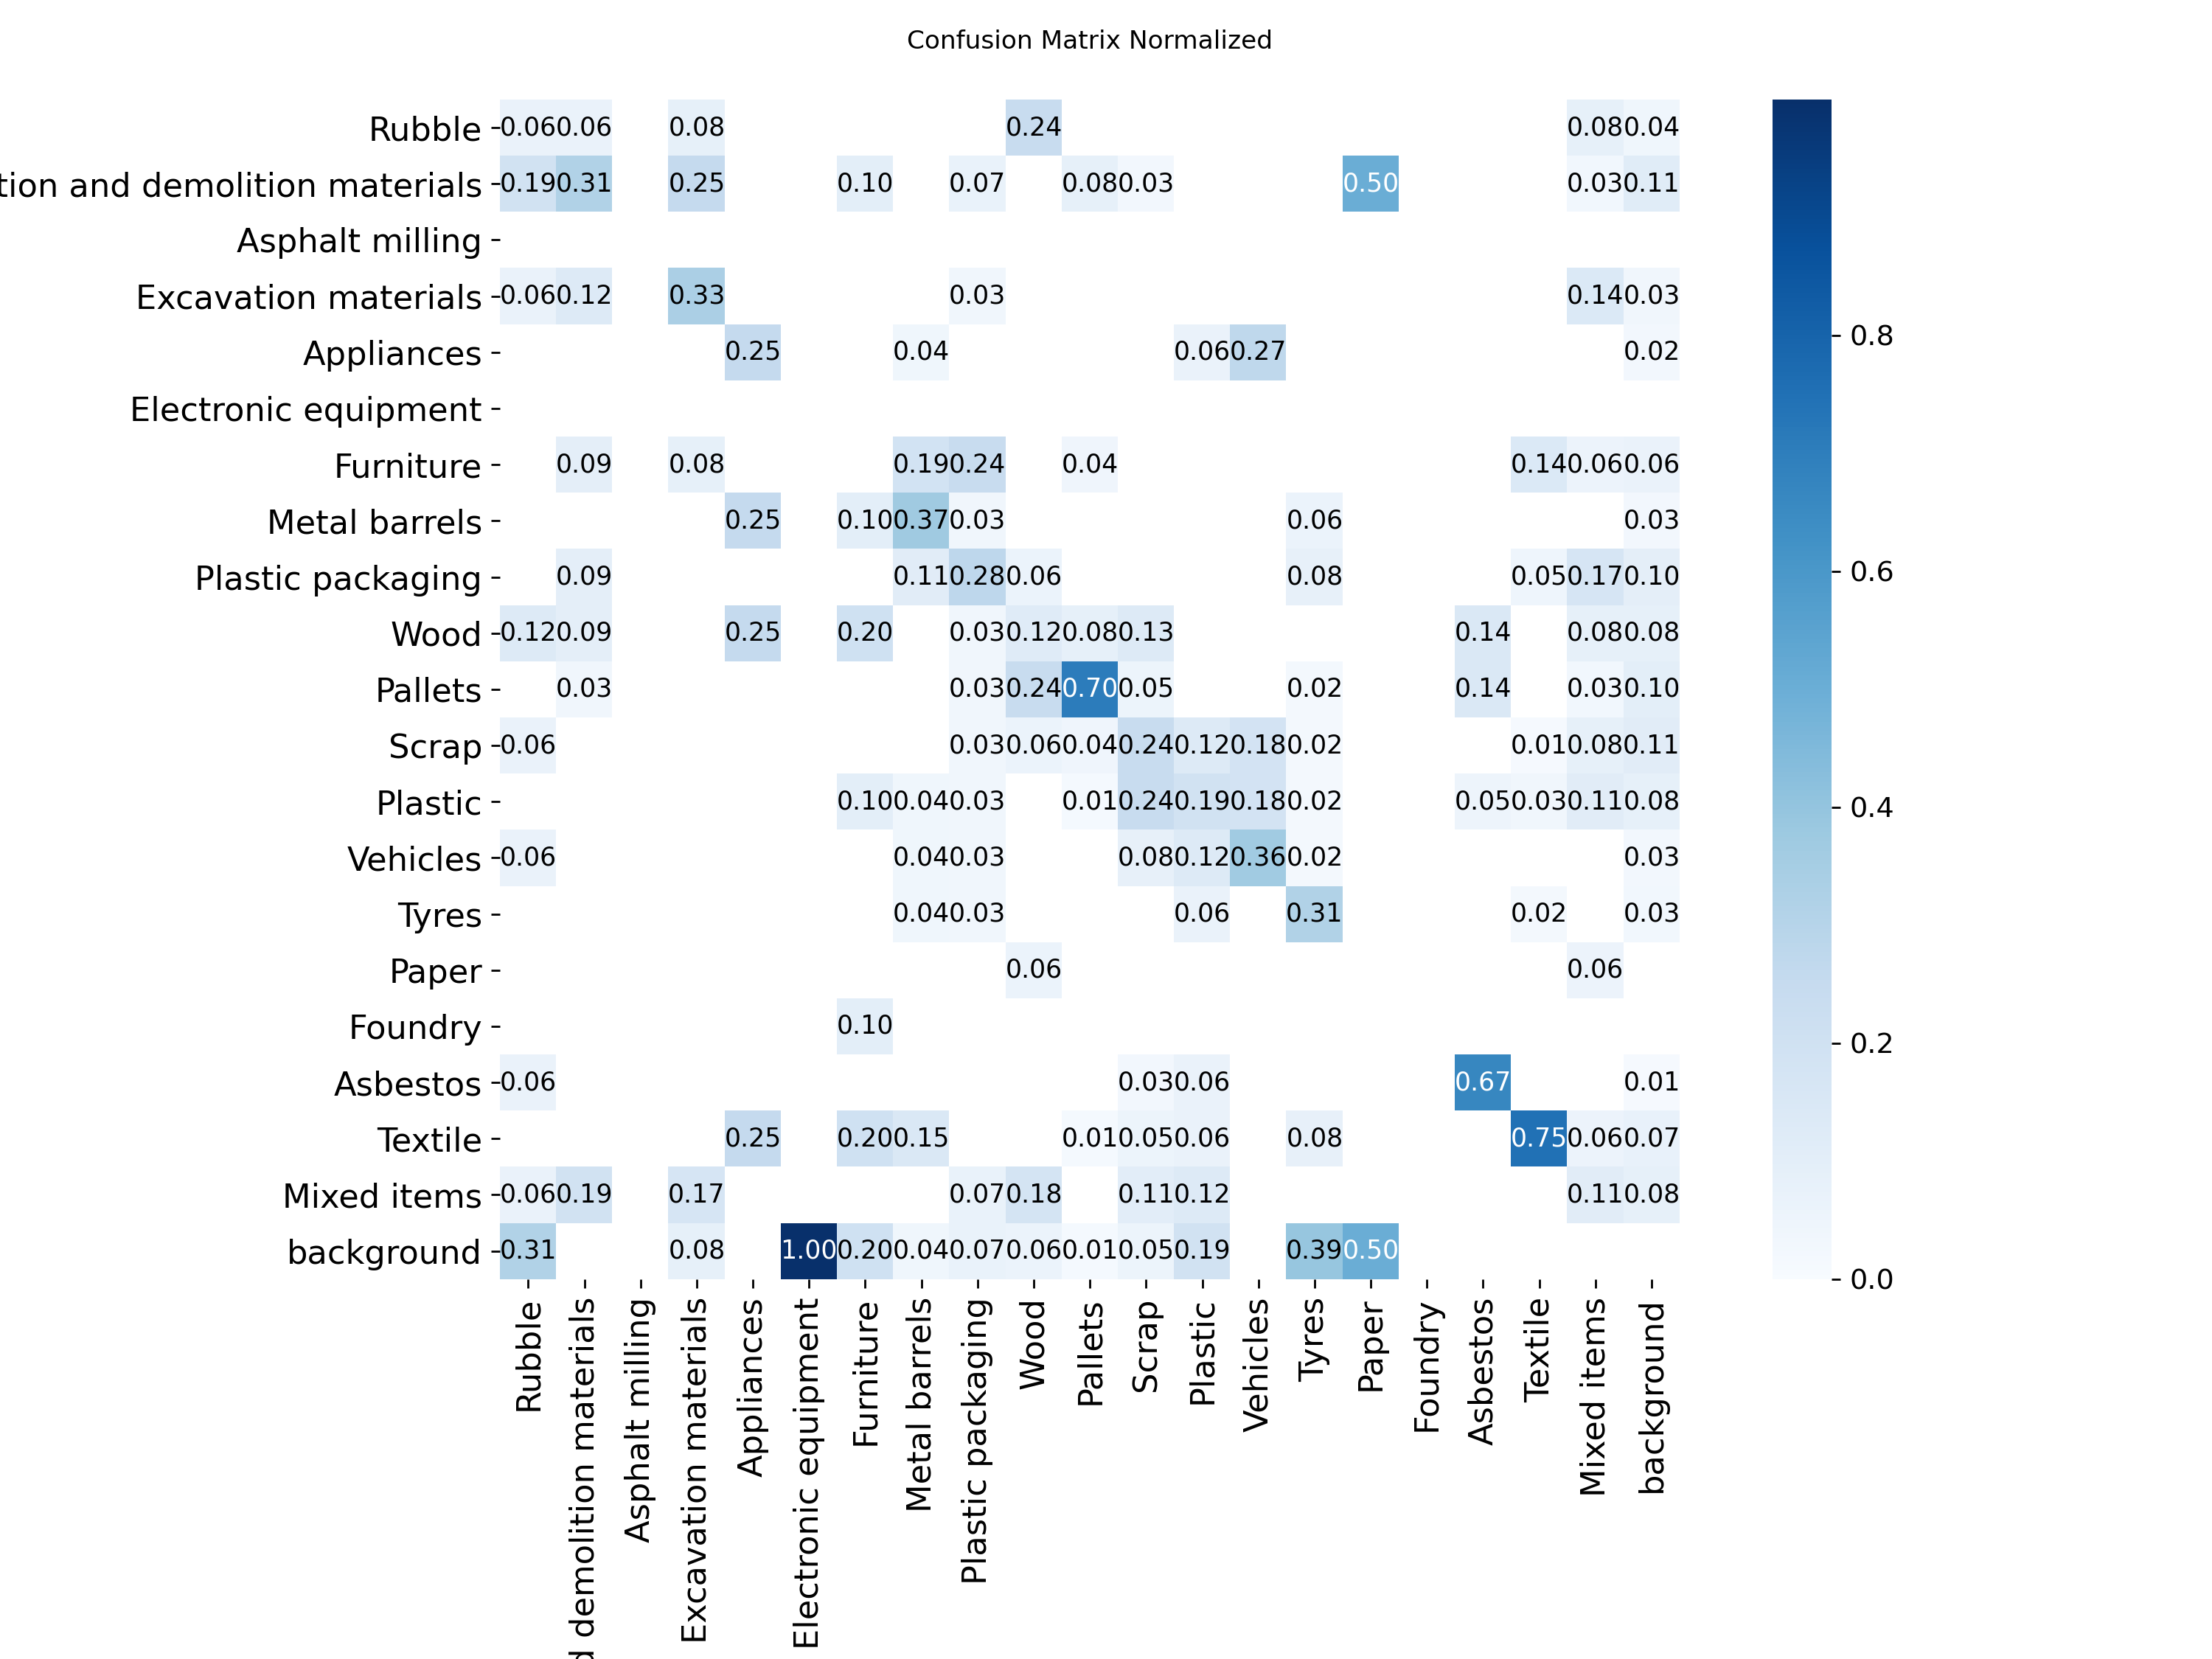

In [ ]:
from pathlib import Path
from IPython.display import display, Image

RUN_DIR = Path(
    "/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2"
)

for filename in [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
]:
    path = RUN_DIR / filename
    if path.exists():
        print(filename)
        display(Image(filename=str(path)))
    else:
        print(f"Missing: {filename}")

## 10. Held-out test evaluation — Fold 1

Evaluate both saved best checkpoints on the same held-out Fold 1 test set and save their metrics and confusion matrices.

# **TESTING FOR BOTH THE MODELS**

In [ ]:
from pathlib import Path
import json
import yaml
import torch
from ultralytics import YOLO

ROOT = Path("/content/drive/MyDrive/DroneWaste")
DATA_YAML = Path(
    "/content/dronewaste_work/yolo_folds/fold_01/dronewaste_fold01.yaml"
)

# Locate the saved checkpoints
possible_checkpoints = {
    "YOLOv12 Nano": [
        ROOT / "results/fold_01/yolo12n/best.pt",
        ROOT / "results/fold_01/yolo12n/weights/best.pt",
    ],
    "YOLOv12 Small": [
        ROOT / "results/fold_01/yolo12s-2/weights/best.pt",
        ROOT / "results/fold_01/yolo12s/weights/best.pt",
    ],
}

checkpoints = {}
for model_name, candidates in possible_checkpoints.items():
    found = next((p for p in candidates if p.is_file()), None)
    if found is None:
        raise FileNotFoundError(
            f"{model_name} checkpoint not found. Checked: {candidates}"
        )
    checkpoints[model_name] = found
    print(f"{model_name}: {found}")

assert torch.cuda.is_available(), "GPU unavailable; select a GPU runtime."
assert DATA_YAML.is_file(), (
    "Dataset YAML is missing. The temporary Colab files may have been reset."
)

with open(DATA_YAML, "r") as f:
    config = yaml.safe_load(f)

dataset_root = Path(config["path"])
test_images = list((dataset_root / config["test"]).glob("*"))

assert len(test_images) == 119, (
    f"Expected 119 site1 test images, found {len(test_images)}"
)

# Confirm the test split really is site1 and matches the saved fold manifest
with open(ROOT / "official_style_cv_manifests.json", "r") as f:
    manifest = json.load(f)

fold1 = next(item for item in manifest["folds"] if item["fold"] == 1)
assert fold1["test_site"] == "site1"
assert len(fold1["test_images"]) == 119

print("\nGPU:", torch.cuda.get_device_name(0))
print("Held-out test site:", fold1["test_site"])
print("Test images:", len(test_images))
print("\nStarting test evaluation only — no training.")

all_results = {}

for model_name, checkpoint in checkpoints.items():
    run_name = "yolo12n" if "Nano" in model_name else "yolo12s"
    output_dir = ROOT / "results" / "fold_01" / "test_site1" / run_name

    print(f"\n{'='*55}\nEvaluating {model_name}\n{'='*55}")

    model = YOLO(str(checkpoint))
    metrics = model.val(
        data=str(DATA_YAML),
        split="test",
        imgsz=640,
        batch=8,
        device=0,
        plots=True,
        project=str(output_dir.parent),
        name=output_dir.name,
        exist_ok=True,
        verbose=True,
    )

    result = {
        "model": model_name,
        "test_site": "site1",
        "test_images": 119,
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50_95": float(metrics.box.map),
        "checkpoint": str(checkpoint),
        "output_dir": str(output_dir),
    }
    all_results[model_name] = result

    with open(output_dir / "test_metrics.json", "w") as f:
        json.dump(result, f, indent=2)

    print(f"\n{model_name} TEST METRICS")
    print(f"Precision:  {result['precision']:.4f}")
    print(f"Recall:     {result['recall']:.4f}")
    print(f"mAP@50:     {result['mAP50']:.4f}")
    print(f"mAP@50–95:  {result['mAP50_95']:.4f}")
    print("Saved to:", output_dir)

# Save combined comparison
comparison_path = (
    ROOT / "results/fold_01/test_site1/comparison_metrics.json"
)
comparison_path.parent.mkdir(parents=True, exist_ok=True)

with open(comparison_path, "w") as f:
    json.dump(all_results, f, indent=2)

print("\nTESTING COMPLETE")
print("Combined metrics:", comparison_path)
print("Test confusion matrices and plots are in each model's output directory.")

YOLOv12 Nano: /content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/best.pt
YOLOv12 Small: /content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/weights/best.pt


AssertionError: GPU unavailable; select a GPU runtime.

In [ ]:
from pathlib import Path
import json

ROOT = Path("/content/drive/MyDrive/DroneWaste")

files_to_check = {
    "YOLOv12 Nano best checkpoint":
        ROOT / "results/fold_01/yolo12n/best.pt",

    "YOLOv12 Small best checkpoint":
        ROOT / "results/fold_01/yolo12s-2/weights/best.pt",

    "Nano test metrics":
        ROOT / "results/fold_01/test_site1/yolo12n/test_metrics.json",

    "Small test metrics":
        ROOT / "results/fold_01/test_site1/yolo12s/test_metrics.json",

    "Nano confusion matrix":
        ROOT / "results/fold_01/test_site1/yolo12n/confusion_matrix.png",

    "Small confusion matrix":
        ROOT / "results/fold_01/test_site1/yolo12s/confusion_matrix.png",

    "Combined comparison JSON":
        ROOT / "results/fold_01/test_site1/comparison_metrics.json",
}

print("=== SAVED FILE VERIFICATION ===\n")

for label, path in files_to_check.items():
    if path.is_file():
        size_mb = path.stat().st_size / (1024 * 1024)
        print(f"✅ SAVED | {label} | {size_mb:.2f} MB")
    else:
        print(f"❌ NOT FOUND | {label} | {path}")

# Read the combined test metrics if present
comparison_path = ROOT / "results/fold_01/test_site1/comparison_metrics.json"

if comparison_path.is_file():
    with open(comparison_path, "r") as f:
        comparison = json.load(f)

    print("\n=== SAVED TEST METRICS ===")
    for model_name, metrics in comparison.items():
        print(f"\n{model_name}")
        for key in ["test_site", "test_images", "precision",
                    "recall", "mAP50", "mAP50_95"]:
            if key in metrics:
                print(f"  {key}: {metrics[key]}")

=== SAVED FILE VERIFICATION ===

✅ SAVED | YOLOv12 Nano best checkpoint | 5.31 MB
✅ SAVED | YOLOv12 Small best checkpoint | 18.07 MB
✅ SAVED | Nano test metrics | 0.00 MB
✅ SAVED | Small test metrics | 0.00 MB
✅ SAVED | Nano confusion matrix | 0.33 MB
✅ SAVED | Small confusion matrix | 0.33 MB
✅ SAVED | Combined comparison JSON | 0.00 MB

=== SAVED TEST METRICS ===

YOLOv12 Nano
  test_site: site1
  test_images: 119
  precision: 0.6121153504074311
  recall: 0.3018508106686925
  mAP50: 0.336904210863758
  mAP50_95: 0.22571977886685113

YOLOv12 Small
  test_site: site1
  test_images: 119
  precision: 0.353923017708525
  recall: 0.296447552729331
  mAP50: 0.3043020668128949
  mAP50_95: 0.21790818571188267


## 11. Results verification and comparison

Review saved metrics, training curves, checkpoint metadata, and output files. These checks support reporting and reproducibility; they do not constitute additional training.

In [ ]:
from pathlib import Path

project_dir = Path("/content/drive/MyDrive/DroneWaste")

print("Project folder exists:", project_dir.exists())
print("\nFolder contents:")
if project_dir.exists():
    for item in sorted(project_dir.iterdir()):
        print(item.name)

Project folder exists: True

Folder contents:
dronewaste_v1.0.json
experiment_config.json
images.tar.gz
official_style_cv_manifests.json
results
sitewise_cv_plan.json
yolo_class_mapping.json
yolo_dataset_metadata.json
yolo_labels


In [ ]:
import pandas as pd
from pathlib import Path

base = Path("/content/drive/MyDrive/DroneWaste/results/fold_01")

runs = {
    "YOLOv12 Nano": base / "yolo12n" / "results.csv",
    "YOLOv12 Small": base / "yolo12s-2" / "results.csv",
}

for name, path in runs.items():
    print("\n" + "=" * 60)
    print(name)

    if not path.exists():
        print(f"CSV not found: {path}")
        continue

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    metric = "metrics/mAP50(B)"
    if metric not in df.columns:
        print("Available columns:", df.columns.tolist())
        continue

    df[metric] = pd.to_numeric(df[metric], errors="coerce")
    best_idx = df[metric].idxmax()

    print(f"Epochs recorded: {len(df)}")
    print(f"Best validation mAP@50: {df.loc[best_idx, metric]:.4f}")
    print(f"Best epoch: {int(df.loc[best_idx, 'epoch'])}")

    print("\nLast 10 epochs:")
    print(
        df[["epoch", metric]]
        .tail(10)
        .to_string(index=False)
    )


YOLOv12 Nano
Epochs recorded: 50
Best validation mAP@50: 0.4539
Best epoch: 50

Last 10 epochs:
 epoch  metrics/mAP50(B)
    41           0.43974
    42           0.45107
    43           0.43321
    44           0.44237
    45           0.44368
    46           0.42890
    47           0.44014
    48           0.45238
    49           0.45038
    50           0.45393

YOLOv12 Small
Epochs recorded: 50
Best validation mAP@50: 0.4207
Best epoch: 50

Last 10 epochs:
 epoch  metrics/mAP50(B)
    41           0.38151
    42           0.36369
    43           0.38714
    44           0.36377
    45           0.39399
    46           0.40302
    47           0.39596
    48           0.41606
    49           0.41278
    50           0.42071


In [ ]:
import pandas as pd
from pathlib import Path

base = Path("/content/drive/MyDrive/DroneWaste/results/fold_01")

runs = {
    "YOLOv12 Nano": base / "yolo12n" / "results.csv",
    "YOLOv12 Small": base / "yolo12s-2" / "results.csv",
}

metrics = [
    "metrics/precision(B)",
    "metrics/recall(B)",
    "metrics/mAP50(B)",
    "metrics/mAP50-95(B)",
    "train/box_loss",
    "val/box_loss",
]

for name, path in runs.items():
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()

    available = [m for m in metrics if m in df.columns]
    for m in available:
        df[m] = pd.to_numeric(df[m], errors="coerce")

    print(f"\n{'=' * 65}\n{name}")
    print("Rows:", len(df))
    print("First epoch value:", df["epoch"].iloc[0])
    print("Last epoch value:", df["epoch"].iloc[-1])

    print("\nLast 5 epochs — loss and detection metrics:")
    print(df[["epoch"] + available].tail(5).to_string(index=False))


YOLOv12 Nano
Rows: 50
First epoch value: 1
Last epoch value: 50

Last 5 epochs — loss and detection metrics:
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)  train/box_loss  val/box_loss
    46               0.62742            0.40310           0.42890              0.30625         0.85219       0.39157
    47               0.63110            0.39983           0.44014              0.31852         0.82181       0.40141
    48               0.64548            0.41174           0.45238              0.32643         0.84900       0.40423
    49               0.63799            0.40788           0.45038              0.32248         0.83347       0.39319
    50               0.66576            0.39587           0.45393              0.32384         0.84802       0.39895

YOLOv12 Small
Rows: 50
First epoch value: 1
Last epoch value: 50

Last 5 epochs — loss and detection metrics:
 epoch  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mA

In [ ]:
from pathlib import Path
import yaml

base = Path("/content/drive/MyDrive/DroneWaste/results/fold_01")

runs = {
    "YOLOv12 Nano": base / "yolo12n",
    "YOLOv12 Small": base / "yolo12s-2",
}

for name, run_dir in runs.items():
    print(f"\n{'=' * 55}")
    print(name)

    checkpoint_candidates = {
        "best.pt": [run_dir / "best.pt", run_dir / "weights" / "best.pt"],
        "last.pt": [run_dir / "last.pt", run_dir / "weights" / "last.pt"],
    }
    for filename, candidates in checkpoint_candidates.items():
        found = next((path for path in candidates if path.is_file()), None)
        print(f"{filename}: {'EXISTS at ' + str(found) if found else 'MISSING'}")

    args_file = run_dir / "args.yaml"
    print(f"args.yaml: {'EXISTS' if args_file.is_file() else 'not present in this run folder'}")

    args_file = run_dir / "args.yaml"
    if args_file.exists():
        with open(args_file) as f:
            args = yaml.safe_load(f)

        for key in ["model", "epochs", "imgsz", "batch", "patience",
                    "optimizer", "lr0", "lrf", "weight_decay"]:
            print(f"{key}: {args.get(key)}")

In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive/DroneWaste/results/fold_01")

for model_name in ["yolo12n", "yolo12s-2"]:
    run_dir = base / model_name

    print(f"\n{'=' * 60}")
    print(f"Searching: {model_name}")

    if not run_dir.exists():
        print("Run directory does not exist.")
        continue

    for path in sorted(run_dir.rglob("*")):
        if path.is_file() and (
            path.name in ["best.pt", "last.pt", "args.yaml", "results.csv"]
        ):
            print(f"{path} ({path.stat().st_size / (1024**2):.2f} MB)")


Searching: yolo12n
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/best.pt (5.31 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/last.pt (5.31 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12n/results.csv (0.01 MB)

Searching: yolo12s-2
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/args.yaml (0.00 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/results.csv (0.01 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/weights/best.pt (18.07 MB)
/content/drive/MyDrive/DroneWaste/results/fold_01/yolo12s-2/weights/last.pt (18.07 MB)


In [ ]:
import torch
from pathlib import Path

base = Path("/content/drive/MyDrive/DroneWaste/results/fold_01")

checkpoints = {
    "YOLOv12 Nano": base / "yolo12n" / "last.pt",
    "YOLOv12 Small": base / "yolo12s-2" / "weights" / "last.pt",
}

for name, path in checkpoints.items():
    print(f"\n{'=' * 50}\n{name}")
    print("Checkpoint exists:", path.exists())

    if path.exists():
        ckpt = torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )
        print("Checkpoint keys:", list(ckpt.keys()))
        print("Epoch stored:", ckpt.get("epoch"))
        print("Optimizer state available:", ckpt.get("optimizer") is not None)
        print("EMA weights available:", ckpt.get("ema") is not None)
        del ckpt


YOLOv12 Nano
Checkpoint exists: True
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Checkpoint keys: ['date', 'version', 'license', 'docs', 'epoch', 'best_fitness', 'stopper', 'model', 'ema', 'updates', 'modelopt', 'optimizer', 'scaler', 'train_args', 'train_metrics', 'train_results', 'git']
Epoch stored: -1
Optimizer state available: False
EMA weights available: False

YOLOv12 Small
Checkpoint exists: True
Checkpoint keys: ['date', 'version', 'license', 'docs', 'epoch', 'best_fitness', 'stopper', 'model', 'ema', 'updates', 'modelopt', 'optimizer', 'scaler', 'train_args', 'train_metrics', 'train_results', 'git']
Epoch stored: -1
Optimizer state available: False
EMA weights available: False


## 12. Current experimental status and reporting notes

- The recorded final comparison is between **YOLOv12 Nano and YOLOv12 Small**.
- The saved Fold 1 test results are based on the held-out site 1 test split.
- The 17-fold manifests define the broader evaluation plan; only Fold 1 results are present in this notebook.
- The earlier YOLOv8 one-epoch smoke test is retained only as a development diagnostic and must not be mixed with the final YOLOv12 results.
- A duplicate source annotation was traced during dataset auditing. Preserve the original dataset and document this observation; do not silently edit the source annotations.
- No model training is triggered by the cleanup itself. Re-run training cells only if you intentionally want a new experiment.
